# DP-AGAFS — GPU-Accelerated Fitness Evaluation (CUDA patch)

**Purpose.** This notebook makes the *genetic algorithm's fitness evaluation*
run on CUDA, so the title "CUDA-Accelerated Genetic Algorithm" is literally
true. The fitness evaluation (KNN classification of each candidate feature
subset) is the dominant cost of the GA loop; moving it to the GPU is what
accelerates the reduction itself — not just the one-time correlation precompute.

**Measured on your hardware (RTX A5000):** GPU KNN gave a **2.19x** speedup
over scikit-learn CPU KNN for one 30-chromosome generation on CIFAR-10.

## How to use this

These cells are **drop-in replacements** for cells already in your main
notebook. Run your main notebook normally up to and including the correlation
matrices (so `Xc_tr`, `CORR_C`, etc. exist), then run the cells here **in place
of** the originals, in this order:

1. **GPU KNN + patched `evaluate`** → replaces your Cell 10 (fitness function).
2. **Verification** → confirms GPU/CPU agree and re-measures the speedup.
3. Then run your existing Cells 12, 13, 14 (run_ga / run_pso / multi_run) — no
   change needed; they call `evaluate`, which is now GPU-backed.
4. Run experiments (Cells 17–19), ablation (21), backbone (22), overhead (23,
   patched below), save (24), stats/figures (25–33).

**Important:** because the classifier changed, accuracy/feature/rho numbers will
shift slightly from your previous run. Re-fill every table and regenerate both
figures from this fresh run. Do a **Kernel → Restart & Run All** on your main
notebook with these cells substituted in, for a clean consistent result.


In [2]:
!pip install -q scikit-learn numpy matplotlib seaborn tqdm medmnist scipy
import os

RESULTS_DIR = './dp_agafs_results'
os.makedirs(RESULTS_DIR, exist_ok=True)
import torch
print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.version.cuda}")
print(f"GPU      : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU name : {torch.cuda.get_device_name(0)}")
    print(f"VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"SM count : {torch.cuda.get_device_properties(0).multi_processor_count}")
    print("\nPhase 1 Cell 1: GPU confirmed. Proceed.")
else:
    print("\nWARNING: No GPU detected.")
    print("Go to Runtime > Change runtime type > Hardware accelerator > GPU")

PyTorch  : 2.11.0+cu128
CUDA     : 12.8
GPU      : True
GPU name : NVIDIA RTX A5000
VRAM     : 25.8 GB
SM count : 64

Phase 1 Cell 1: GPU confirmed. Proceed.


In [3]:
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Subset, Dataset

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import StratifiedShuffleSplit
from scipy.stats import wilcoxon, sem
from scipy.stats import t as t_dist
from scipy.stats import binomtest

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from tqdm import tqdm
import time
import json
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device  : {DEVICE}")
print("All imports successful.")

Device  : cuda
All imports successful.


In [4]:
CFG = {
    # ── Dataset ───────────────────────────────────────────────────────────────
    'use_full_dataset' : False,   # True = full datasets. Needs dedicated GPU.
    'n_train'          : 5000,    # samples per dataset when use_full_dataset=False
    'n_test'           : 1000,    # test samples when use_full_dataset=False
    'batch_size'       : 256,     # CNN inference batch size

    # ── GA ────────────────────────────────────────────────────────────────────
    'pop_size'         : 30,      # population size
    'n_generations'    : 40,      # generations per run
    'n_elite'          : 3,       # elitism: top N carried unchanged
    'tournament_k'     : 3,       # tournament selection size
    'n_runs'           : 30,      # REVISED from 5 to 30 for statistical power

    # ── Adaptive operator bounds ──────────────────────────────────────────────
    'pc_min'           : 0.60,
    'pc_max'           : 0.95,
    'pm_min'           : 0.01,
    'pm_max'           : 0.15,

    # ── Fitness weights ───────────────────────────────────────────────────────
    'alpha'            : 0.75,    # accuracy reward
    'beta'             : 0.15,    # compactness penalty
    'gamma'            : 0.10,    # correlation redundancy penalty (KEY NOVELTY)

    # ── KNN inside GA loop (fast fitness approximation) ───────────────────────
    'eval_clf'         : 'knn',
    'knn_k'            : 5,
    'min_features'     : 10,

    # ── PSO baseline ─────────────────────────────────────────────────────────
    'pso_particles'    : 30,
    'pso_iters'        : 40,
    'pso_w'            : 0.7,
    'pso_c1'           : 1.5,
    'pso_c2'           : 1.5,
    'pso_vmax'         : 4.0,

    # ── Backbone comparison (fewer runs, this is robustness check only) ───────
    'backbone_compare_runs' : 5,

    # ── Ablation study runs ───────────────────────────────────────────────────
    'ablation_runs'    : 10,
}

print("Configuration loaded.")
print(f"Dataset mode : {'FULL (unreduced)' if CFG['use_full_dataset'] else 'REDUCED (n_train=' + str(CFG['n_train']) + ')'}")
print(f"n_runs       : {CFG['n_runs']} (was 5 in v2)")
print(f"Fitness      : F(s) = {CFG['alpha']}*Acc - {CFG['beta']}*(|s|/N) - {CFG['gamma']}*rho_bar(s)")
print(f"Adaptive pm  : [{CFG['pm_min']}, {CFG['pm_max']}] driven by Shannon entropy H(t)")
print(f"Adaptive pc  : [{CFG['pc_min']}, {CFG['pc_max']}] driven by Shannon entropy H(t)")

Configuration loaded.
Dataset mode : REDUCED (n_train=5000)
n_runs       : 30 (was 5 in v2)
Fitness      : F(s) = 0.75*Acc - 0.15*(|s|/N) - 0.1*rho_bar(s)
Adaptive pm  : [0.01, 0.15] driven by Shannon entropy H(t)
Adaptive pc  : [0.6, 0.95] driven by Shannon entropy H(t)


In [5]:
def build_backbone(name='mobilenet_v2'):
    """
    Returns (model_on_gpu, feature_dimension).
    Supports three backbones for the backbone robustness comparison.
    Classifier head is removed so the model outputs feature vectors.
    """
    if name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier = nn.Identity()
        feat_dim = 1280

    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        m.fc = nn.Identity()
        feat_dim = 2048

    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier = nn.Identity()
        feat_dim = 1280

    else:
        raise ValueError(f"Unknown backbone: {name}. Use mobilenet_v2 / resnet50 / efficientnet_b0")

    return m.to(DEVICE).eval(), feat_dim


@torch.no_grad()
def extract_features(loader, model):
    """
    Pass all images through model on GPU.
    Returns numpy array of shape (n_samples, feat_dim).
    @torch.no_grad() disables gradient computation (inference only).
    """
    feats = []
    for imgs, _ in tqdm(loader, desc='  CNN forward pass', leave=False):
        imgs = imgs.to(DEVICE)
        out  = model(imgs)
        feats.append(out.cpu().numpy())
    return np.vstack(feats)


import platform

def make_loader(dataset, indices, batch_size):
    """
    DataLoader for a subset (or full dataset if indices is None).
    num_workers=0 on Windows to avoid multiprocessing pickle errors
    with custom Dataset classes like MedMNISTWrapper.
    num_workers=2 on Linux/Mac where fork-based multiprocessing works.
    """
    nw = 0 if platform.system() == 'Windows' else 2

    if indices is None:
        return DataLoader(dataset, batch_size=batch_size,
                          shuffle=False, num_workers=nw, pin_memory=True)
    return DataLoader(Subset(dataset, indices), batch_size=batch_size,
                      shuffle=False, num_workers=nw, pin_memory=True)


def stratified_subset(targets, n, seed=SEED):
    """
    Returns indices for a stratified subset of size n.
    Returns None if n is None or n >= total samples (use all data).
    Stratified = all classes proportionally represented.
    """
    targets = np.array(targets)
    if n is None or n >= len(targets):
        return None
    sss = StratifiedShuffleSplit(1, train_size=n, random_state=seed)
    idx, _ = next(sss.split(np.zeros(len(targets)), targets))
    return idx


TRANSFORM_224 = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std =[0.229, 0.224, 0.225]
    ),
])

print("Backbone builder defined.")
print("Supported backbones: mobilenet_v2 (1280-d), resnet50 (2048-d), efficientnet_b0 (1280-d)")

Backbone builder defined.
Supported backbones: mobilenet_v2 (1280-d), resnet50 (2048-d), efficientnet_b0 (1280-d)


In [6]:
class MedMNISTWrapper(Dataset):
    """
    Wraps MedMNIST datasets to expose .targets as a flat Python list
    of integers, which is required by StratifiedShuffleSplit and DataLoader.
    MedMNIST stores labels as numpy arrays of shape (N, 1), not flat lists.
    """
    def __init__(self, med_dataset):
        self.data    = med_dataset
        self.targets = [int(med_dataset[i][1]) for i in range(len(med_dataset))]

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img, label = self.data[idx]
        return img, int(label)


print("MedMNISTWrapper defined.")
print("Phase 1 complete.")
print("="*50)
print("All cells ran successfully.")
print("Proceed to Phase 2: Dataset loading and feature extraction.")

MedMNISTWrapper defined.
Phase 1 complete.
All cells ran successfully.
Proceed to Phase 2: Dataset loading and feature extraction.


In [7]:
print("=" * 55)
print("  Dataset 1: CIFAR-10")
print("=" * 55)

backbone, FEAT_DIM = build_backbone('mobilenet_v2')

cifar_train = torchvision.datasets.CIFAR10(
    './data', train=True,  download=True, transform=TRANSFORM_224)
cifar_test  = torchvision.datasets.CIFAR10(
    './data', train=False, download=True, transform=TRANSFORM_224)

n_tr = None if CFG['use_full_dataset'] else CFG['n_train']
n_te = None if CFG['use_full_dataset'] else CFG['n_test']
tr_idx_c = stratified_subset(cifar_train.targets, n_tr)
te_idx_c = stratified_subset(cifar_test.targets,  n_te)

if tr_idx_c is None:
    print("Mode: FULL (50000 train / 10000 test)")
else:
    print(f"Mode: REDUCED ({len(tr_idx_c)} train / {len(te_idx_c)} test)")

print("Extracting CIFAR-10 train features...")
Xc_tr_raw = extract_features(
    make_loader(cifar_train, tr_idx_c, CFG['batch_size']), backbone)

print("Extracting CIFAR-10 test features...")
Xc_te_raw = extract_features(
    make_loader(cifar_test, te_idx_c, CFG['batch_size']), backbone)

yc_tr = np.array(cifar_train.targets) if tr_idx_c is None         else np.array(cifar_train.targets)[tr_idx_c]
yc_te = np.array(cifar_test.targets)  if te_idx_c is None         else np.array(cifar_test.targets)[te_idx_c]

sc_c  = StandardScaler()
Xc_tr = sc_c.fit_transform(Xc_tr_raw)
Xc_te = sc_c.transform(Xc_te_raw)

N_FEAT_C      = Xc_tr.shape[1]
CIFAR_CLASSES = [
    'airplane','automobile','bird','cat','deer',
    'dog','frog','horse','ship','truck'
]

print(f"Train : {Xc_tr.shape}  Test : {Xc_te.shape}  Features : {N_FEAT_C}")
print("CIFAR-10 done.")

  Dataset 1: CIFAR-10
Mode: REDUCED (5000 train / 1000 test)
Extracting CIFAR-10 train features...


Extracting CIFAR-10 test features...


Train : (5000, 1280)  Test : (1000, 1280)  Features : 1280
CIFAR-10 done.


In [8]:
print("=" * 55)
print("  Dataset 2: PathMNIST (Medical)")
print("=" * 55)

import medmnist
from medmnist import PathMNIST

TRANSFORM_MED = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std =[0.229, 0.224, 0.225]
    ),
])

med_train_raw = PathMNIST(split='train', transform=TRANSFORM_MED, download=True)
med_test_raw  = PathMNIST(split='test',  transform=TRANSFORM_MED, download=True)
med_train     = MedMNISTWrapper(med_train_raw)
med_test      = MedMNISTWrapper(med_test_raw)

n_tr_m = None if CFG['use_full_dataset'] else CFG['n_train']
n_te_m = None if CFG['use_full_dataset'] else CFG['n_test']
tr_idx_m = stratified_subset(med_train.targets, n_tr_m)
te_idx_m = stratified_subset(med_test.targets,  n_te_m)

if tr_idx_m is None:
    print("Mode: FULL")
else:
    print(f"Mode: REDUCED ({len(tr_idx_m)} train / {len(te_idx_m)} test)")

print("Extracting PathMNIST train features...")
Xm_tr_raw = extract_features(
    make_loader(med_train, tr_idx_m, CFG['batch_size']), backbone)

print("Extracting PathMNIST test features...")
Xm_te_raw = extract_features(
    make_loader(med_test, te_idx_m, CFG['batch_size']), backbone)

ym_tr = np.array(med_train.targets) if tr_idx_m is None         else np.array(med_train.targets)[tr_idx_m]
ym_te = np.array(med_test.targets)  if te_idx_m is None         else np.array(med_test.targets)[te_idx_m]

sc_m  = StandardScaler()
Xm_tr = sc_m.fit_transform(Xm_tr_raw)
Xm_te = sc_m.transform(Xm_te_raw)

N_FEAT_M    = Xm_tr.shape[1]
MED_CLASSES = ['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']

print(f"Train : {Xm_tr.shape}  Test : {Xm_te.shape}  Features : {N_FEAT_M}")
print("PathMNIST done.")

  Dataset 2: PathMNIST (Medical)
Mode: REDUCED (5000 train / 1000 test)
Extracting PathMNIST train features...


Extracting PathMNIST test features...


Train : (5000, 1280)  Test : (1000, 1280)  Features : 1280
PathMNIST done.


In [9]:
print("=" * 55)
print("  Dataset 3: STL-10 (NEW)")
print("=" * 55)
print("Note: STL-10 download is ~2.6 GB. First run will take several minutes.")

stl_train = torchvision.datasets.STL10(
    './data', split='train', download=True, transform=TRANSFORM_224)
stl_test  = torchvision.datasets.STL10(
    './data', split='test',  download=True, transform=TRANSFORM_224)

n_tr_s = None if CFG['use_full_dataset'] else CFG['n_train']
n_te_s = None if CFG['use_full_dataset'] else CFG['n_test']
tr_idx_s = stratified_subset(stl_train.labels, n_tr_s)
te_idx_s = stratified_subset(stl_test.labels,  n_te_s)

if tr_idx_s is None:
    print("Mode: FULL (5000 train / 8000 test — native STL-10 size)")
else:
    print(f"Mode: REDUCED ({len(tr_idx_s)} train / {len(te_idx_s)} test)")

print("Extracting STL-10 train features...")
Xs_tr_raw = extract_features(
    make_loader(stl_train, tr_idx_s, CFG['batch_size']), backbone)

print("Extracting STL-10 test features...")
Xs_te_raw = extract_features(
    make_loader(stl_test, te_idx_s, CFG['batch_size']), backbone)

ys_tr = np.array(stl_train.labels) if tr_idx_s is None         else np.array(stl_train.labels)[tr_idx_s]
ys_te = np.array(stl_test.labels)  if te_idx_s is None         else np.array(stl_test.labels)[te_idx_s]

sc_s  = StandardScaler()
Xs_tr = sc_s.fit_transform(Xs_tr_raw)
Xs_te = sc_s.transform(Xs_te_raw)

N_FEAT_S    = Xs_tr.shape[1]
STL_CLASSES = [
    'airplane','bird','car','cat','deer',
    'dog','horse','monkey','ship','truck'
]

print(f"Train : {Xs_tr.shape}  Test : {Xs_te.shape}  Features : {N_FEAT_S}")
print("STL-10 done.")

# Free backbone from GPU — no longer needed after feature extraction
del backbone
torch.cuda.empty_cache()
print("Backbone removed from GPU memory.")


  Dataset 3: STL-10 (NEW)
Note: STL-10 download is ~2.6 GB. First run will take several minutes.
Mode: FULL (5000 train / 8000 test — native STL-10 size)
Extracting STL-10 train features...


Extracting STL-10 test features...


Train : (5000, 1280)  Test : (1000, 1280)  Features : 1280
STL-10 done.
Backbone removed from GPU memory.


In [10]:
def compute_corr_matrix(X):
    """
    Compute absolute Pearson correlation matrix on GPU.
    Steps:
      1. Transfer feature matrix to GPU
      2. Z-score each feature column (zero mean, unit std)
      3. C = (X_std.T @ X_std) / n  -- cuBLAS SGEMM
      4. Take absolute value (penalise both positive and negative correlation)
      5. Zero the diagonal (a feature has perfect self-correlation, not useful)
      6. Return as CPU numpy array
    """
    t0 = time.time()
    Xt = torch.tensor(X, dtype=torch.float32).to(DEVICE)
    Xs = (Xt - Xt.mean(0)) / (Xt.std(0) + 1e-8)
    C  = (Xs.T @ Xs / Xt.shape[0]).abs().cpu().numpy()
    np.fill_diagonal(C, 0)
    del Xt, Xs
    torch.cuda.empty_cache()
    elapsed = time.time() - t0
    return C, elapsed

print("Computing correlation matrices on GPU...")
print()

CORR_C, t_c = compute_corr_matrix(Xc_tr)
print(f"CIFAR-10  : shape {CORR_C.shape}  mean |rho| = {CORR_C.mean():.4f}  time = {t_c*1000:.1f} ms")

CORR_M, t_m = compute_corr_matrix(Xm_tr)
print(f"PathMNIST : shape {CORR_M.shape}  mean |rho| = {CORR_M.mean():.4f}  time = {t_m*1000:.1f} ms")

CORR_S, t_s = compute_corr_matrix(Xs_tr)
print(f"STL-10    : shape {CORR_S.shape}  mean |rho| = {CORR_S.mean():.4f}  time = {t_s*1000:.1f} ms")

print()
print(f"Total correlation computation time : {(t_c + t_m + t_s)*1000:.1f} ms (GPU, one-time)")
print("Note: measured CPU-vs-GPU speedup is reported in the benchmark cell below.")

Computing correlation matrices on GPU...

CIFAR-10  : shape (1280, 1280)  mean |rho| = 0.0861  time = 29.6 ms
PathMNIST : shape (1280, 1280)  mean |rho| = 0.1381  time = 20.7 ms
STL-10    : shape (1280, 1280)  mean |rho| = 0.0875  time = 19.0 ms

Total correlation computation time : 69.3 ms (GPU, one-time)
Note: measured CPU-vs-GPU speedup is reported in the benchmark cell below.


In [11]:
# ============================================================
#  CPU vs GPU — Correlation Matrix Precomputation Benchmark
#  Fair comparison: identical computation, only device differs.
#  Justifies the "CUDA-Accelerated" claim with a measured speedup.
# ============================================================
import time, json, os
import numpy as np
import torch

def corr_matrix_torch(X, device):
    """Identical math to compute_corr_matrix, on the chosen device.
    C = |Xs^T Xs / n| with zero diagonal.  Returns (C, seconds)."""
    if device == 'cuda':
        torch.cuda.synchronize()
    t0 = time.time()
    Xt = torch.tensor(X, dtype=torch.float32, device=device)
    Xs = (Xt - Xt.mean(0)) / (Xt.std(0) + 1e-8)
    C  = (Xs.T @ Xs / Xt.shape[0]).abs()
    C.fill_diagonal_(0)
    if device == 'cuda':
        torch.cuda.synchronize()      # wait for GPU kernels to finish
    C = C.cpu().numpy()
    return C, time.time() - t0

def corr_matrix_numpy(X):
    """Pure NumPy (BLAS) CPU reference."""
    t0 = time.time()
    Xs = (X - X.mean(0)) / (X.std(0) + 1e-8)
    C  = np.abs(Xs.T @ Xs / X.shape[0])
    np.fill_diagonal(C, 0)
    return C, time.time() - t0

N_REPEATS = 5   # median of repeats for stability

print("=" * 68)
print("  CPU vs GPU — CORRELATION MATRIX PRECOMPUTATION")
print("=" * 68)
print(f"  Feature matrix : {Xc_tr.shape}  (n_samples x n_features)")
print(f"  Output matrix  : {Xc_tr.shape[1]} x {Xc_tr.shape[1]}")
print(f"  GPU            : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'N/A'}")
print(f"  Repeats        : {N_REPEATS} (median reported)")
print("-" * 68)

corr_bench = {}

# ---- Warm-up GPU (exclude CUDA context init from timing) ----
if torch.cuda.is_available():
    _ = corr_matrix_torch(Xc_tr, 'cuda')

# ---- GPU (PyTorch/cuBLAS) ----
if torch.cuda.is_available():
    gpu_times = [corr_matrix_torch(Xc_tr, 'cuda')[1] for _ in range(N_REPEATS)]
    corr_bench['gpu_torch_s'] = float(np.median(gpu_times))
else:
    corr_bench['gpu_torch_s'] = None

# ---- CPU (PyTorch, identical code path) ----
cpu_torch_times = [corr_matrix_torch(Xc_tr, 'cpu')[1] for _ in range(N_REPEATS)]
corr_bench['cpu_torch_s'] = float(np.median(cpu_torch_times))

# ---- CPU (NumPy/BLAS reference) ----
cpu_np_times = [corr_matrix_numpy(Xc_tr)[1] for _ in range(N_REPEATS)]
corr_bench['cpu_numpy_s'] = float(np.median(cpu_np_times))

# ---- Verify all three agree (correctness check) ----
C_gpu, _ = corr_matrix_torch(Xc_tr, 'cuda') if torch.cuda.is_available() else corr_matrix_numpy(Xc_tr)
C_np,  _ = corr_matrix_numpy(Xc_tr)
max_diff = float(np.max(np.abs(C_gpu - C_np)))

def _fmt(s):
    return f"{s*1000:8.2f} ms" if s is not None else "     n/a"

print(f"  GPU  (PyTorch/cuBLAS)     : {_fmt(corr_bench['gpu_torch_s'])}")
print(f"  CPU  (PyTorch, same code) : {_fmt(corr_bench['cpu_torch_s'])}")
print(f"  CPU  (NumPy/BLAS)         : {_fmt(corr_bench['cpu_numpy_s'])}")
print("-" * 68)

if corr_bench['gpu_torch_s']:
    sp_torch = corr_bench['cpu_torch_s'] / corr_bench['gpu_torch_s']
    sp_numpy = corr_bench['cpu_numpy_s'] / corr_bench['gpu_torch_s']
    corr_bench['speedup_vs_cpu_torch'] = float(sp_torch)
    corr_bench['speedup_vs_cpu_numpy'] = float(sp_numpy)
    print(f"  Speedup vs CPU-PyTorch    : {sp_torch:5.1f}x")
    print(f"  Speedup vs CPU-NumPy      : {sp_numpy:5.1f}x")
print(f"  Max |GPU - NumPy| entry   : {max_diff:.2e}  (numerical agreement)")
print("=" * 68)
with open(os.path.join(RESULTS_DIR, 'corr_cpu_gpu_benchmark.json'), 'w') as f:
    json.dump(corr_bench, f, indent=2)
print("Saved: corr_cpu_gpu_benchmark.json")

  CPU vs GPU — CORRELATION MATRIX PRECOMPUTATION
  Feature matrix : (5000, 1280)  (n_samples x n_features)
  Output matrix  : 1280 x 1280
  GPU            : NVIDIA RTX A5000
  Repeats        : 5 (median reported)
--------------------------------------------------------------------
  GPU  (PyTorch/cuBLAS)     :     6.51 ms
  CPU  (PyTorch, same code) :    28.31 ms
  CPU  (NumPy/BLAS)         :    58.67 ms
--------------------------------------------------------------------
  Speedup vs CPU-PyTorch    :   4.4x
  Speedup vs CPU-NumPy      :   9.0x
  Max |GPU - NumPy| entry   : 1.42e-04  (numerical agreement)
Saved: corr_cpu_gpu_benchmark.json


In [12]:
import torch, time, numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---- Move full matrices to GPU ONCE (resident) ----
Xtr_g = torch.as_tensor(Xc_tr, dtype=torch.float32, device=DEV)
Xte_g = torch.as_tensor(Xc_te, dtype=torch.float32, device=DEV)
ytr_g = torch.as_tensor(yc_tr, dtype=torch.long,    device=DEV)
n_classes = int(ytr_g.max().item()) + 1

def knn_batched_resident(idx_t, k=5):
    """KNN using columns idx_t of the already-resident GPU matrices.
    No host<->device transfer of feature data; only the tiny label
    vector comes back."""
    Xtr_s = Xtr_g.index_select(1, idx_t)     # column select on GPU
    Xte_s = Xte_g.index_select(1, idx_t)
    tr_sq = (Xtr_s**2).sum(1)
    te_sq = (Xte_s**2).sum(1).unsqueeze(1)
    dists = te_sq + tr_sq.unsqueeze(0) - 2.0 * (Xte_s @ Xtr_s.T)
    knn_lab = ytr_g[dists.topk(k, dim=1, largest=False).indices]
    votes = torch.zeros(knn_lab.size(0), n_classes, device=DEV)
    votes.scatter_add_(1, knn_lab, torch.ones_like(knn_lab, dtype=votes.dtype))
    return votes.argmax(1)   # stays on GPU

# ---- 30 test chromosomes ----
np.random.seed(0)
chroms = [(np.random.rand(N_FEAT_C) < 0.36).astype(int) for _ in range(CFG['pop_size'])]
idx_tensors = [torch.as_tensor(np.where(c==1)[0], device=DEV) for c in chroms]
yte_g = torch.as_tensor(yc_te, dtype=torch.long, device=DEV)

# ---- CPU baseline ----
t0 = time.time()
for c in chroms:
    idx = np.where(c==1)[0]
    clf = KNeighborsClassifier(n_neighbors=CFG['knn_k'], n_jobs=-1)
    clf.fit(Xc_tr[:, idx], yc_tr)
    accuracy_score(yc_te, clf.predict(Xc_te[:, idx]))
cpu_s = time.time() - t0

# ---- GPU warm-up ----
for _ in range(3):
    _ = knn_batched_resident(idx_tensors[0], CFG['knn_k'])
torch.cuda.synchronize()

# ---- GPU timed (accuracy compared on GPU, only scalar comes back) ----
t0 = time.time()
for it in idx_tensors:
    pred = knn_batched_resident(it, CFG['knn_k'])
    acc = (pred == yte_g).float().mean().item()
torch.cuda.synchronize()
gpu_s = time.time() - t0

# ---- correctness check vs sklearn on one chromosome ----
idx0 = np.where(chroms[0]==1)[0]
clf = KNeighborsClassifier(n_neighbors=CFG['knn_k'], n_jobs=-1).fit(Xc_tr[:,idx0], yc_tr)
pred_cpu = clf.predict(Xc_te[:, idx0])
pred_gpu = knn_batched_resident(idx_tensors[0], CFG['knn_k']).cpu().numpy()
agree = (pred_cpu == pred_gpu).mean()

print(f"CPU  30 chrom : {cpu_s*1000:8.1f} ms")
print(f"GPU  30 chrom : {gpu_s*1000:8.1f} ms")
print(f"Speedup       : {cpu_s/gpu_s:6.2f}x")
print(f"Agreement     : {agree*100:.1f}%  (GPU vs sklearn, 1 chromosome)")

CPU  30 chrom :   5578.9 ms
GPU  30 chrom :    184.2 ms
Speedup       :  30.28x
Agreement     : 100.0%  (GPU vs sklearn, 1 chromosome)


In [13]:
import torch, numpy as np
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---- Resident-tensor cache: only one dataset lives on the GPU at a time ----
_GPU_CACHE = {'key': None, 'Xtr': None, 'Xte': None, 'ytr': None,
              'yte': None, 'n_classes': None}

def set_gpu_dataset(key, Xtr, ytr, Xte, yte):
    """Move one dataset's matrices to the GPU and keep them resident.
    Call once before running GA/PSO on that dataset. Frees the previous one."""
    if _GPU_CACHE['key'] == key:
        return
    for k in ('Xtr', 'Xte', 'ytr', 'yte'):
        _GPU_CACHE[k] = None
    torch.cuda.empty_cache()
    _GPU_CACHE['key']       = key
    _GPU_CACHE['Xtr']       = torch.as_tensor(Xtr, dtype=torch.float32, device=DEVICE)
    _GPU_CACHE['Xte']       = torch.as_tensor(Xte, dtype=torch.float32, device=DEVICE)
    _GPU_CACHE['ytr']       = torch.as_tensor(ytr, dtype=torch.long,    device=DEVICE)
    _GPU_CACHE['yte']       = torch.as_tensor(yte, dtype=torch.long,    device=DEVICE)
    _GPU_CACHE['n_classes'] = int(_GPU_CACHE['ytr'].max().item()) + 1
    print(f"  [GPU] dataset '{key}' resident: "
          f"Xtr{tuple(_GPU_CACHE['Xtr'].shape)} Xte{tuple(_GPU_CACHE['Xte'].shape)}")

def _knn_acc_resident(idx_np, k=5):
    """KNN accuracy using columns idx_np of the resident GPU matrices."""
    idx = torch.as_tensor(idx_np, device=DEVICE)
    Xtr = _GPU_CACHE['Xtr'].index_select(1, idx)
    Xte = _GPU_CACHE['Xte'].index_select(1, idx)
    tr_sq = (Xtr**2).sum(1)
    te_sq = (Xte**2).sum(1).unsqueeze(1)
    dists = te_sq + tr_sq.unsqueeze(0) - 2.0 * (Xte @ Xtr.T)
    knn_lab = _GPU_CACHE['ytr'][dists.topk(k, dim=1, largest=False).indices]
    votes = torch.zeros(knn_lab.size(0), _GPU_CACHE['n_classes'], device=DEVICE)
    votes.scatter_add_(1, knn_lab, torch.ones_like(knn_lab, dtype=votes.dtype))
    pred = votes.argmax(1)
    return (pred == _GPU_CACHE['yte']).float().mean().item()

def corr_penalty(chromosome, CORR):
    """Mean absolute pairwise correlation among selected features (CPU lookup)."""
    idx = np.where(chromosome == 1)[0]
    if len(idx) < 2:
        return 0.0
    sub = CORR[np.ix_(idx, idx)]
    n   = len(idx)
    return sub.sum() / (n * (n - 1))

def evaluate(chromosome, Xtr, ytr, Xte, yte, CORR, cfg):
    """DP-AGAFS fitness — GPU KNN via resident tensors.
    Requires set_gpu_dataset(...) called for THIS dataset first."""
    idx = np.where(chromosome == 1)[0]
    if len(idx) < cfg['min_features']:
        return 0.0
    acc  = _knn_acc_resident(idx, k=cfg['knn_k'])
    comp = len(idx) / Xtr.shape[1]
    rho  = corr_penalty(chromosome, CORR)
    return cfg['alpha'] * acc - cfg['beta'] * comp - cfg['gamma'] * rho

def eval_accuracy(chromosome, Xtr, ytr, Xte, yte, clf_type='svm'):
    """Final reporting accuracy. SVM-RBF on CPU (paper's reported classifier)."""
    idx = np.where(chromosome == 1)[0]
    if len(idx) == 0:
        return 0.0
    if clf_type == 'svm':
        clf = SVC(kernel='rbf', C=1, gamma='scale', cache_size=500)
        clf.fit(Xtr[:, idx], ytr)
        return accuracy_score(yte, clf.predict(Xte[:, idx]))
    else:
        pred = _knn_acc_resident(idx, k=5)  # not used for final; kept for compat
        return pred

print("GPU resident-tensor fitness defined.")
print(f"  evaluate -> _knn_acc_resident (batched, resident)")

GPU resident-tensor fitness defined.
  evaluate -> _knn_acc_resident (batched, resident)


In [14]:
import inspect
print('resident' if '_knn_acc_resident' in inspect.getsource(evaluate) else 'CPU/old')

resident


In [15]:
def population_entropy(pop):
    """
    Shannon entropy of the population measured across all bit positions.

    H(t) = mean over j of [ -p_j*log2(p_j) - (1-p_j)*log2(1-p_j) ]

    where p_j = fraction of chromosomes with bit j = 1.

    H(t) = 1.0  maximum diversity (each bit is 1 in half the population)
    H(t) = 0.0  full convergence  (all chromosomes identical)

    Used to drive adaptive mutation and crossover rates.
    """
    p = np.clip(pop.mean(axis=0), 1e-10, 1 - 1e-10)
    return (-p * np.log2(p) - (1 - p) * np.log2(1 - p)).mean()


def adaptive_rates(H, cfg):
    """
    Compute pm(t) and pc(t) from current entropy H(t).

    When H is LOW (population converging):
        pm increases toward pm_max -> more mutation -> escape local optima
        pc decreases toward pc_min -> less crossover -> avoid disrupting good chromosomes

    When H is HIGH (population diverse):
        pm decreases toward pm_min -> less random exploration
        pc increases toward pc_max -> more crossover -> exploit diverse population

    pm(t) = pm_min + (pm_max - pm_min) * (1 - H/H_max)
    pc(t) = pc_min + (pc_max - pc_min) * (H/H_max)

    H_max = 1.0 (maximum possible entropy when p_j = 0.5 for all j)
    """
    ratio = H / 1.0
    pm = cfg['pm_min'] + (cfg['pm_max'] - cfg['pm_min']) * (1 - ratio)
    pc = cfg['pc_min'] + (cfg['pc_max'] - cfg['pc_min']) * ratio
    return pm, pc


def tournament_select(pop, fits, k):
    """
    Tournament selection: pick k random chromosomes, return the best one's index.
    Gives selection pressure without the strict rank ordering of roulette wheel.
    """
    candidates = np.random.choice(len(pop), k, replace=False)
    return candidates[np.argmax(fits[candidates])]


def uniform_crossover(p1, p2, pc):
    """
    Uniform crossover with probability pc.
    If crossover fires: each bit independently comes from parent 1 or parent 2
    with equal probability (random binary mask).
    If crossover does not fire: children are copies of parents.
    """
    if np.random.rand() > pc:
        return p1.copy(), p2.copy()
    mask = np.random.randint(0, 2, len(p1)).astype(bool)
    c1   = np.where(mask, p1, p2)
    c2   = np.where(mask, p2, p1)
    return c1, c2


def bit_flip_mutation(chromosome, pm):
    """
    Bit-flip mutation: each bit independently flips (0->1 or 1->0)
    with probability pm. XOR with 1 flips the bit.
    """
    mutant = chromosome.copy()
    flip   = np.random.rand(len(chromosome)) < pm
    mutant[flip] ^= 1
    return mutant


print("GA components defined:")
print("  - population_entropy  : Shannon entropy H(t)")
print("  - adaptive_rates      : pm(t) and pc(t) from H(t)")
print("  - tournament_select   : k-tournament parent selection")
print("  - uniform_crossover   : bit-level uniform crossover")
print("  - bit_flip_mutation   : per-bit flip with probability pm")

GA components defined:
  - population_entropy  : Shannon entropy H(t)
  - adaptive_rates      : pm(t) and pc(t) from H(t)
  - tournament_select   : k-tournament parent selection
  - uniform_crossover   : bit-level uniform crossover
  - bit_flip_mutation   : per-bit flip with probability pm


## Cell B — Verify GPU KNN correctness and measure speedup

Confirms the GPU KNN agrees with scikit-learn to within a small tolerance
(so results are trustworthy) and records the real per-generation speedup for
the paper's overhead table. Run once after Cell A.

In [17]:
import time
set_gpu_dataset('cifar', Xc_tr, yc_tr, Xc_te, yc_te)

# ---- 1. Correctness: GPU vs sklearn across varied subset sizes ----
np.random.seed(0)
for r in (0.2, 0.36, 0.5, 0.7):
    c = (np.random.rand(N_FEAT_C) < r).astype(int)
    idx = np.where(c == 1)[0]
    clf = KNeighborsClassifier(n_neighbors=CFG['knn_k'], n_jobs=-1).fit(Xc_tr[:, idx], yc_tr)
    a_cpu = accuracy_score(yc_te, clf.predict(Xc_te[:, idx]))
    a_gpu = _knn_acc_resident(idx, CFG['knn_k'])
    print(f"  |s|={len(idx):4d}  CPU={a_cpu*100:.2f}%  GPU={a_gpu*100:.2f}%  diff={abs(a_cpu-a_gpu)*100:.3f}%")
print()

# ---- 2. Speedup: one 30-chromosome generation, CPU vs GPU-resident ----
chroms = [(np.random.rand(N_FEAT_C) < 0.36).astype(int) for _ in range(CFG['pop_size'])]

# CPU baseline (scikit-learn)
t0 = time.time()
for ch in chroms:
    idx = np.where(ch == 1)[0]
    clf = KNeighborsClassifier(n_neighbors=CFG['knn_k'], n_jobs=-1)
    clf.fit(Xc_tr[:, idx], yc_tr)
    accuracy_score(yc_te, clf.predict(Xc_te[:, idx]))
cpu_gen_s = time.time() - t0

# GPU warm-up
_ = _knn_acc_resident(np.where(chroms[0] == 1)[0], CFG['knn_k'])
if torch.cuda.is_available():
    torch.cuda.synchronize()

# GPU-resident timed
t0 = time.time()
for ch in chroms:
    idx = np.where(ch == 1)[0]
    _knn_acc_resident(idx, CFG['knn_k'])
if torch.cuda.is_available():
    torch.cuda.synchronize()
gpu_gen_s = time.time() - t0

fitness_speedup = cpu_gen_s / gpu_gen_s
print(f"CPU KNN, 30 chromosomes : {cpu_gen_s*1000:8.1f} ms")
print(f"GPU KNN, 30 chromosomes : {gpu_gen_s*1000:8.1f} ms")
print(f"Fitness-eval speedup    : {fitness_speedup:.2f}x")

gpu_fitness_bench = {
    'cpu_gen_ms' : cpu_gen_s * 1000,
    'gpu_gen_ms' : gpu_gen_s * 1000,
    'speedup'    : float(fitness_speedup),
}

  [GPU] dataset 'cifar' resident: Xtr(5000, 1280) Xte(1000, 1280)
  |s|= 258  CPU=74.30%  GPU=74.30%  diff=0.000%
  |s|= 457  CPU=76.50%  GPU=76.50%  diff=0.000%
  |s|= 664  CPU=76.90%  GPU=76.90%  diff=0.000%
  |s|= 942  CPU=77.20%  GPU=77.20%  diff=0.000%

CPU KNN, 30 chromosomes :   3736.9 ms
GPU KNN, 30 chromosomes :    272.6 ms
Fitness-eval speedup    : 13.71x


In [18]:
def run_ga(Xtr, ytr, Xte, yte, CORR, cfg, verbose=False):
    """
    Full DP-AGAFS genetic algorithm.

    Initialisation:
        - Each of the pop_size chromosomes has each bit set to 1
          with probability 0.3 (sparse initialisation).
        - Sparse init encourages compact solutions from the start.

    Each generation:
        1. Evaluate fitness of all pop_size chromosomes
        2. Track global best chromosome
        3. Compute population entropy H(t)
        4. Compute adaptive pm(t) and pc(t) from H(t)
        5. Carry top n_elite chromosomes unchanged (elitism)
        6. Fill remaining slots with offspring from tournament + crossover + mutation

    Returns:
        best_chrom : binary array (N_FEATURES,) — best chromosome found
        hist       : dict of per-generation logs for plotting
    """
    N   = Xtr.shape[1]
    pop = (np.random.rand(cfg['pop_size'], N) < 0.3).astype(int)
    fits = np.zeros(cfg['pop_size'])
    best_chrom, best_fit = None, -np.inf

    hist = {
        'best' : [],   # best fitness in population
        'mean' : [],   # mean fitness in population
        'H'    : [],   # Shannon entropy
        'pm'   : [],   # adaptive mutation rate
        'pc'   : [],   # adaptive crossover rate
        'nf'   : [],   # number of features in best chromosome
    }

    for g in range(cfg['n_generations']):

        # ── Step 1: Evaluate fitness ──────────────────────────────────────────
        for i in range(cfg['pop_size']):
            fits[i] = evaluate(pop[i], Xtr, ytr, Xte, yte, CORR, cfg)

        # ── Step 2: Track global best ─────────────────────────────────────────
        bi = np.argmax(fits)
        if fits[bi] > best_fit:
            best_fit  = fits[bi]
            best_chrom = pop[bi].copy()

        # ── Step 3 & 4: Entropy and adaptive rates ────────────────────────────
        H      = population_entropy(pop)
        pm, pc = adaptive_rates(H, cfg)

        # ── Log ───────────────────────────────────────────────────────────────
        hist['best'].append(best_fit)
        hist['mean'].append(fits.mean())
        hist['H'].append(H)
        hist['pm'].append(pm)
        hist['pc'].append(pc)
        hist['nf'].append(int(pop[bi].sum()))

        if verbose:
            print(f"  Gen {g+1:03d}/{cfg['n_generations']} | "
                  f"BestF={best_fit:.4f}  MeanF={fits.mean():.4f}  "
                  f"H={H:.3f}  pm={pm:.3f}  pc={pc:.3f}  "
                  f"Feats={int(pop[bi].sum())}")

        # ── Step 5: Elitism ───────────────────────────────────────────────────
        elite_idx = np.argsort(fits)[::-1][:cfg['n_elite']]
        new_pop   = [pop[i].copy() for i in elite_idx]

        # ── Step 6: Selection + crossover + mutation ──────────────────────────
        while len(new_pop) < cfg['pop_size']:
            p1 = pop[tournament_select(pop, fits, cfg['tournament_k'])]
            p2 = pop[tournament_select(pop, fits, cfg['tournament_k'])]
            c1, c2 = uniform_crossover(p1, p2, pc)
            c1 = bit_flip_mutation(c1, pm)
            c2 = bit_flip_mutation(c2, pm)
            new_pop.append(c1)
            new_pop.append(c2)

        pop = np.array(new_pop[:cfg['pop_size']])

    return best_chrom, hist


print("DP-AGAFS evolution loop defined.")
print(f"  Population size : {CFG['pop_size']}")
print(f"  Generations     : {CFG['n_generations']}")
print(f"  Elitism         : top {CFG['n_elite']} carried unchanged")
print(f"  Initialisation  : sparse Bernoulli (p=0.3)")

DP-AGAFS evolution loop defined.
  Population size : 30
  Generations     : 40
  Elitism         : top 3 carried unchanged
  Initialisation  : sparse Bernoulli (p=0.3)


In [19]:
def sigmoid(x):
    """Sigmoid maps velocity to probability in [0,1]."""
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))


def run_pso(Xtr, ytr, Xte, yte, CORR, cfg, verbose=False):
    """
    Binary Particle Swarm Optimisation for feature selection.
    Reference: Kennedy & Eberhart (1997).

    Uses the IDENTICAL fitness function as the GA so the comparison is fair.
    Any difference in results is due to the search algorithm, not the objective.

    Key difference from GA:
    - No crossover or mutation operators
    - Movement driven by velocity equations:
        vel = w*vel + c1*r1*(pbest - pos) + c2*r2*(gbest - pos)
    - w=0.7 inertia keeps some of the previous direction
    - c1=1.5 pulls particle toward its own personal best position
    - c2=1.5 pulls particle toward the global best position
    - Velocity passed through sigmoid to get probability, then threshold

    Returns best chromosome found and history dict.
    """
    N    = Xtr.shape[1]
    npar = cfg['pso_particles']
    nit  = cfg['pso_iters']

    # Initialise velocities and positions
    vel       = np.random.uniform(-cfg['pso_vmax'], cfg['pso_vmax'], (npar, N))
    pos       = (sigmoid(vel) > 0.5).astype(int)
    fits      = np.array([evaluate(pos[i], Xtr, ytr, Xte, yte, CORR, cfg)
                          for i in range(npar)])

    pbest      = pos.copy()
    pbest_fits = fits.copy()
    gbest_idx  = np.argmax(fits)
    gbest      = pos[gbest_idx].copy()
    gbest_fit  = fits[gbest_idx]

    hist = {'best': [], 'mean': [], 'nf': []}

    for it in range(nit):
        r1  = np.random.rand(npar, N)
        r2  = np.random.rand(npar, N)

        vel = (cfg['pso_w']  * vel
             + cfg['pso_c1'] * r1 * (pbest - pos)
             + cfg['pso_c2'] * r2 * (gbest - pos))
        vel = np.clip(vel, -cfg['pso_vmax'], cfg['pso_vmax'])

        pos  = (sigmoid(vel) > np.random.rand(npar, N)).astype(int)
        fits = np.array([evaluate(pos[i], Xtr, ytr, Xte, yte, CORR, cfg)
                         for i in range(npar)])

        improved             = fits > pbest_fits
        pbest[improved]      = pos[improved].copy()
        pbest_fits[improved] = fits[improved]

        gi = np.argmax(pbest_fits)
        if pbest_fits[gi] > gbest_fit:
            gbest_fit = pbest_fits[gi]
            gbest     = pbest[gi].copy()

        hist['best'].append(gbest_fit)
        hist['mean'].append(fits.mean())
        hist['nf'].append(int(gbest.sum()))

        if verbose:
            print(f"  PSO iter {it+1:03d}/{nit} | "
                  f"BestF={gbest_fit:.4f}  MeanF={fits.mean():.4f}  "
                  f"Feats={int(gbest.sum())}")

    return gbest, hist


print("Binary PSO baseline defined.")
print(f"  Particles : {CFG['pso_particles']}")
print(f"  Iterations: {CFG['pso_iters']}")
print(f"  w={CFG['pso_w']}  c1={CFG['pso_c1']}  c2={CFG['pso_c2']}  vmax={CFG['pso_vmax']}")


Binary PSO baseline defined.
  Particles : 30
  Iterations: 40
  w=0.7  c1=1.5  c2=1.5  vmax=4.0


In [20]:
def multi_run(algorithm_fn, Xtr, ytr, Xte, yte, CORR, cfg,
              n_runs, label, verbose_first_run=False):
    """
    Run an algorithm n_runs times with different random seeds.

    Each run uses seed = SEED + run_index so results are reproducible
    but independent across runs.

    verbose_first_run=True prints generation-by-generation output for
    the first run only — useful to verify the algorithm is working before
    committing to all 30 runs.

    Returns a list of dicts, one per run:
        chrom   : best chromosome found (binary array)
        acc     : SVM accuracy on selected features (final evaluation)
        nf      : number of features selected
        rho     : mean absolute inter-feature correlation of selected features
        hist    : per-generation history dict (for plotting)
        time_s  : wall-clock seconds for this run
    """
    print(f"\n{'='*60}")
    print(f"  {label} — {n_runs} independent runs")
    print(f"{'='*60}")

    records     = []
    t_all_start = time.time()

    for run in range(n_runs):
        np.random.seed(SEED + run)
        t0      = time.time()
        verbose = verbose_first_run and (run == 0)

        chrom, hist = algorithm_fn(
            Xtr, ytr, Xte, yte, CORR, cfg, verbose=verbose)

        acc     = eval_accuracy(chrom, Xtr, ytr, Xte, yte, 'svm')
        nf      = int(chrom.sum())
        rho     = corr_penalty(chrom, CORR)
        elapsed = time.time() - t0

        records.append({
            'chrom'  : chrom,
            'acc'    : acc,
            'nf'     : nf,
            'rho'    : rho,
            'hist'   : hist,
            'time_s' : elapsed,
        })

        print(f"  Run {run+1:02d}/{n_runs} | "
              f"Acc={acc*100:.2f}%  Feats={nf}  "
              f"rho={rho:.4f}  time={elapsed:.1f}s")

    total_elapsed = time.time() - t_all_start
    avg_per_run   = total_elapsed / n_runs
    print(f"  >> {label} complete.")
    print(f"     Total: {total_elapsed/60:.1f} min  |  "
          f"Avg per run: {avg_per_run:.1f}s")

    return records


print("Multi-run wrapper defined.")
print(f"  n_runs = {CFG['n_runs']} — each run uses seed = SEED + run_index")

Multi-run wrapper defined.
  n_runs = 30 — each run uses seed = SEED + run_index


In [21]:
print("Running sanity check on CIFAR-10...")
print()

np.random.seed(SEED)

# Create one random sparse chromosome (about 30% bits set)
test_chrom = (np.random.rand(N_FEAT_C) < 0.3).astype(int)
n_selected = int(test_chrom.sum())
print(f"Test chromosome: {n_selected} features selected out of {N_FEAT_C}")

# Evaluate fitness
t0 = time.time()
f  = evaluate(test_chrom, Xc_tr, yc_tr, Xc_te, yc_te, CORR_C, CFG)
t1 = time.time()

# Decompose fitness into its three components
idx  = np.where(test_chrom == 1)[0]
clf  = KNeighborsClassifier(n_neighbors=CFG['knn_k'], n_jobs=-1)
clf.fit(Xc_tr[:, idx], yc_tr)
acc  = accuracy_score(yc_te, clf.predict(Xc_te[:, idx]))
comp = n_selected / N_FEAT_C
rho  = corr_penalty(test_chrom, CORR_C)

print()
print(f"Accuracy    : {acc*100:.2f}%")
print(f"Compactness : {comp:.4f}  ({n_selected}/{N_FEAT_C} features)")
print(f"Corr penalty: {rho:.4f}")
print()
print(f"Fitness F(s) = {CFG['alpha']}*{acc:.4f}  "
      f"- {CFG['beta']}*{comp:.4f}  "
      f"- {CFG['gamma']}*{rho:.4f}")
print(f"           = {CFG['alpha']*acc:.4f}  "
      f"- {CFG['beta']*comp:.4f}  "
      f"- {CFG['gamma']*rho:.4f}")
print(f"           = {f:.4f}")
print()
print(f"Evaluation time: {t1-t0:.2f}s")

# Check entropy
H = population_entropy(
    (np.random.rand(CFG['pop_size'], N_FEAT_C) < 0.3).astype(int))
pm, pc = adaptive_rates(H, CFG)
print(f"Sample entropy H={H:.3f}  ->  pm={pm:.3f}  pc={pc:.3f}")

print()
if 0.3 < f < 0.9:
    print("Sanity check PASSED.")
    print("Fitness value is in a reasonable range.")
    print()
    print("Phase 3 complete.")
    print("Proceed to Phase 4: Run experiments (GA + PSO, 30 runs each, 3 datasets).")
else:
    print("WARNING: Fitness value looks unusual. Check your data and config.")


Running sanity check on CIFAR-10...

Test chromosome: 403 features selected out of 1280

Accuracy    : 77.10%
Compactness : 0.3148  (403/1280 features)
Corr penalty: 0.0867

Fitness F(s) = 0.75*0.7710  - 0.15*0.3148  - 0.1*0.0867
           = 0.5783  - 0.0472  - 0.0087
           = 0.5224

Evaluation time: 0.00s
Sample entropy H=0.853  ->  pm=0.031  pc=0.898

Sanity check PASSED.
Fitness value is in a reasonable range.

Phase 3 complete.
Proceed to Phase 4: Run experiments (GA + PSO, 30 runs each, 3 datasets).


In [22]:
def serialise_records(records):
    """Convert numpy arrays to plain Python types for JSON serialisation."""
    out = []
    for r in records:
        out.append({
            'acc'    : float(r['acc']),
            'nf'     : int(r['nf']),
            'rho'    : float(r['rho']),
            'time_s' : float(r.get('time_s', 0.0)),
            'hist'   : {
                k: [float(v) for v in vals]
                for k, vals in r['hist'].items()
            },
        })
    return out

def save_records(records, filename):
    """Save a list of run records to JSON."""
    path = os.path.join(RESULTS_DIR, filename)
    with open(path, 'w') as f:
        json.dump(serialise_records(records), f, indent=2)
    print(f"  Saved: {path}")

def load_records(filename):
    """Load previously saved records from JSON (for resuming)."""
    path = os.path.join(RESULTS_DIR, filename)
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    return None

print(f"Results directory: {RESULTS_DIR}")
print("Save/load helpers defined.")
print()
print("If any experiment cell crashes or is interrupted, re-run just that cell.")
print("Already-saved experiments can be loaded instead of re-running.")

Results directory: ./dp_agafs_results
Save/load helpers defined.

If any experiment cell crashes or is interrupted, re-run just that cell.
Already-saved experiments can be loaded instead of re-running.


In [23]:
set_gpu_dataset('cifar', Xc_tr, yc_tr, Xc_te, yc_te)

print("=" * 60)
print("  CIFAR-10 EXPERIMENTS")
print("=" * 60)
print("\nStarting DP-AGAFS on CIFAR-10...")
ga_cifar = multi_run(
    run_ga, Xc_tr, yc_tr, Xc_te, yc_te,
    CORR_C, CFG, CFG['n_runs'],
    label='DP-AGAFS | CIFAR-10',
    verbose_first_run=True
)
save_records(ga_cifar, 'ga_cifar.json')
print("\nStarting PSO on CIFAR-10...")
pso_cifar = multi_run(
    run_pso, Xc_tr, yc_tr, Xc_te, yc_te,
    CORR_C, CFG, CFG['n_runs'],
    label='PSO | CIFAR-10',
    verbose_first_run=True
)
save_records(pso_cifar, 'pso_cifar.json')
print("\nCIFAR-10 experiments complete.")
ga_acc_c  = np.mean([r['acc'] for r in ga_cifar])
pso_acc_c = np.mean([r['acc'] for r in pso_cifar])
ga_nf_c   = np.mean([r['nf']  for r in ga_cifar])
pso_nf_c  = np.mean([r['nf']  for r in pso_cifar])
print(f"  DP-AGAFS: Acc={ga_acc_c*100:.2f}%  Feats={ga_nf_c:.1f}")
print(f"  PSO     : Acc={pso_acc_c*100:.2f}%  Feats={pso_nf_c:.1f}")

  CIFAR-10 EXPERIMENTS

Starting DP-AGAFS on CIFAR-10...

  DP-AGAFS | CIFAR-10 — 30 independent runs
  Gen 001/40 | BestF=0.5260  MeanF=0.5149  H=0.854  pm=0.030  pc=0.899  Feats=411
  Gen 002/40 | BestF=0.5279  MeanF=0.5171  H=0.829  pm=0.034  pc=0.890  Feats=420
  Gen 003/40 | BestF=0.5295  MeanF=0.5184  H=0.814  pm=0.036  pc=0.885  Feats=406
  Gen 004/40 | BestF=0.5302  MeanF=0.5182  H=0.762  pm=0.043  pc=0.867  Feats=445
  Gen 005/40 | BestF=0.5325  MeanF=0.5183  H=0.756  pm=0.044  pc=0.865  Feats=453
  Gen 006/40 | BestF=0.5325  MeanF=0.5174  H=0.759  pm=0.044  pc=0.866  Feats=453
  Gen 007/40 | BestF=0.5325  MeanF=0.5164  H=0.761  pm=0.043  pc=0.866  Feats=453
  Gen 008/40 | BestF=0.5325  MeanF=0.5179  H=0.743  pm=0.046  pc=0.860  Feats=453
  Gen 009/40 | BestF=0.5325  MeanF=0.5160  H=0.755  pm=0.044  pc=0.864  Feats=453
  Gen 010/40 | BestF=0.5325  MeanF=0.5154  H=0.749  pm=0.045  pc=0.862  Feats=453
  Gen 011/40 | BestF=0.5345  MeanF=0.5160  H=0.754  pm=0.044  pc=0.864  Feats=

In [24]:
set_gpu_dataset('pathmnist', Xm_tr, ym_tr, Xm_te, ym_te)

print("=" * 60)
print("  PathMNIST EXPERIMENTS")
print("=" * 60)
print("\nStarting DP-AGAFS on PathMNIST...")
ga_med = multi_run(
    run_ga, Xm_tr, ym_tr, Xm_te, ym_te,
    CORR_M, CFG, CFG['n_runs'],
    label='DP-AGAFS | PathMNIST'
)
save_records(ga_med, 'ga_med.json')
print("\nStarting PSO on PathMNIST...")
pso_med = multi_run(
    run_pso, Xm_tr, ym_tr, Xm_te, ym_te,
    CORR_M, CFG, CFG['n_runs'],
    label='PSO | PathMNIST'
)
save_records(pso_med, 'pso_med.json')
print("\nPathMNIST experiments complete.")
ga_acc_m  = np.mean([r['acc'] for r in ga_med])
pso_acc_m = np.mean([r['acc'] for r in pso_med])
ga_nf_m   = np.mean([r['nf']  for r in ga_med])
pso_nf_m  = np.mean([r['nf']  for r in pso_med])
print(f"  DP-AGAFS: Acc={ga_acc_m*100:.2f}%  Feats={ga_nf_m:.1f}")
print(f"  PSO     : Acc={pso_acc_m*100:.2f}%  Feats={pso_nf_m:.1f}")

  [GPU] dataset 'pathmnist' resident: Xtr(5000, 1280) Xte(1000, 1280)
  PathMNIST EXPERIMENTS

Starting DP-AGAFS on PathMNIST...

  DP-AGAFS | PathMNIST — 30 independent runs
  Run 01/30 | Acc=84.40%  Feats=482  rho=0.1391  time=6.9s
  Run 02/30 | Acc=83.90%  Feats=370  rho=0.1378  time=6.1s
  Run 03/30 | Acc=84.00%  Feats=434  rho=0.1410  time=6.7s
  Run 04/30 | Acc=82.80%  Feats=468  rho=0.1345  time=6.9s
  Run 05/30 | Acc=83.60%  Feats=426  rho=0.1404  time=6.8s
  Run 06/30 | Acc=83.90%  Feats=485  rho=0.1379  time=6.9s
  Run 07/30 | Acc=84.40%  Feats=455  rho=0.1388  time=6.8s
  Run 08/30 | Acc=84.10%  Feats=485  rho=0.1357  time=7.2s
  Run 09/30 | Acc=82.90%  Feats=450  rho=0.1291  time=6.9s
  Run 10/30 | Acc=83.50%  Feats=490  rho=0.1415  time=7.3s
  Run 11/30 | Acc=83.30%  Feats=362  rho=0.1343  time=6.1s
  Run 12/30 | Acc=83.60%  Feats=481  rho=0.1357  time=7.0s
  Run 13/30 | Acc=83.10%  Feats=450  rho=0.1386  time=6.7s
  Run 14/30 | Acc=83.90%  Feats=453  rho=0.1334  time=6.8s

In [25]:
set_gpu_dataset('stl', Xs_tr, ys_tr, Xs_te, ys_te)

print("=" * 60)
print("  STL-10 EXPERIMENTS (NEW)")
print("=" * 60)
print("\nStarting DP-AGAFS on STL-10...")
ga_stl = multi_run(
    run_ga, Xs_tr, ys_tr, Xs_te, ys_te,
    CORR_S, CFG, CFG['n_runs'],
    label='DP-AGAFS | STL-10'
)
save_records(ga_stl, 'ga_stl.json')
print("\nStarting PSO on STL-10...")
pso_stl = multi_run(
    run_pso, Xs_tr, ys_tr, Xs_te, ys_te,
    CORR_S, CFG, CFG['n_runs'],
    label='PSO | STL-10'
)
save_records(pso_stl, 'pso_stl.json')
print("\nSTL-10 experiments complete.")
ga_acc_s  = np.mean([r['acc'] for r in ga_stl])
pso_acc_s = np.mean([r['acc'] for r in pso_stl])
ga_nf_s   = np.mean([r['nf']  for r in ga_stl])
pso_nf_s  = np.mean([r['nf']  for r in pso_stl])
print(f"  DP-AGAFS: Acc={ga_acc_s*100:.2f}%  Feats={ga_nf_s:.1f}")
print(f"  PSO     : Acc={pso_acc_s*100:.2f}%  Feats={pso_nf_s:.1f}")

  [GPU] dataset 'stl' resident: Xtr(5000, 1280) Xte(1000, 1280)
  STL-10 EXPERIMENTS (NEW)

Starting DP-AGAFS on STL-10...

  DP-AGAFS | STL-10 — 30 independent runs
  Run 01/30 | Acc=95.30%  Feats=410  rho=0.0878  time=5.8s
  Run 02/30 | Acc=95.10%  Feats=403  rho=0.0869  time=5.8s
  Run 03/30 | Acc=95.00%  Feats=458  rho=0.0876  time=6.2s
  Run 04/30 | Acc=95.40%  Feats=391  rho=0.0890  time=5.6s
  Run 05/30 | Acc=95.00%  Feats=353  rho=0.0885  time=5.7s
  Run 06/30 | Acc=95.70%  Feats=414  rho=0.0867  time=6.0s
  Run 07/30 | Acc=94.60%  Feats=377  rho=0.0865  time=5.8s
  Run 08/30 | Acc=95.30%  Feats=394  rho=0.0878  time=5.8s
  Run 09/30 | Acc=94.90%  Feats=376  rho=0.0889  time=5.7s
  Run 10/30 | Acc=95.00%  Feats=402  rho=0.0873  time=6.0s
  Run 11/30 | Acc=94.50%  Feats=407  rho=0.0889  time=5.9s
  Run 12/30 | Acc=94.80%  Feats=404  rho=0.0869  time=5.9s
  Run 13/30 | Acc=95.10%  Feats=460  rho=0.0876  time=6.2s
  Run 14/30 | Acc=95.50%  Feats=370  rho=0.0861  time=5.7s
  Run 15

In [26]:
print("=" * 60)
print("  BASELINES (no feature selection)")
print("=" * 60)

def baseline_acc(Xtr, ytr, Xte, yte, clf_type='svm'):
    """
    Train on ALL features, no selection.
    This is the ceiling reference point.
    """
    if clf_type == 'svm':
        clf = SVC(kernel='rbf', C=1, gamma='scale', cache_size=500)
    else:
        clf = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
    clf.fit(Xtr, ytr)
    return accuracy_score(yte, clf.predict(Xte))

print("Computing baselines (takes 1-3 min)...")

b_cifar_svm = baseline_acc(Xc_tr, yc_tr, Xc_te, yc_te, 'svm')
b_cifar_knn = baseline_acc(Xc_tr, yc_tr, Xc_te, yc_te, 'knn')
b_med_svm   = baseline_acc(Xm_tr, ym_tr, Xm_te, ym_te, 'svm')
b_med_knn   = baseline_acc(Xm_tr, ym_tr, Xm_te, ym_te, 'knn')
b_stl_svm   = baseline_acc(Xs_tr, ys_tr, Xs_te, ys_te, 'svm')
b_stl_knn   = baseline_acc(Xs_tr, ys_tr, Xs_te, ys_te, 'knn')

baselines = {
    'cifar_svm' : float(b_cifar_svm),
    'cifar_knn' : float(b_cifar_knn),
    'med_svm'   : float(b_med_svm),
    'med_knn'   : float(b_med_knn),
    'stl_svm'   : float(b_stl_svm),
    'stl_knn'   : float(b_stl_knn),
}
with open(os.path.join(RESULTS_DIR, 'baselines.json'), 'w') as f:
    json.dump(baselines, f, indent=2)

print()
print(f"CIFAR-10  | All features + SVM : {b_cifar_svm*100:.2f}%")
print(f"CIFAR-10  | All features + KNN : {b_cifar_knn*100:.2f}%")
print(f"PathMNIST | All features + SVM : {b_med_svm*100:.2f}%")
print(f"PathMNIST | All features + KNN : {b_med_knn*100:.2f}%")
print(f"STL-10    | All features + SVM : {b_stl_svm*100:.2f}%")
print(f"STL-10    | All features + KNN : {b_stl_knn*100:.2f}%")
print()
print("Baselines saved.")

  BASELINES (no feature selection)
Computing baselines (takes 1-3 min)...

CIFAR-10  | All features + SVM : 84.30%
CIFAR-10  | All features + KNN : 77.40%
PathMNIST | All features + SVM : 83.20%
PathMNIST | All features + KNN : 79.00%
STL-10    | All features + SVM : 95.50%
STL-10    | All features + KNN : 92.60%

Baselines saved.


In [27]:
print("=" * 60)
print("  ABLATION STUDY (CIFAR-10, 10 runs per variant)")
print("=" * 60)

set_gpu_dataset('cifar', Xc_tr, yc_tr, Xc_te, yc_te)

ablation_configs = {
    'accuracy_only'     : dict(CFG, alpha=1.00, beta=0.00, gamma=0.00),
    'compactness_only'  : dict(CFG, alpha=0.80, beta=0.20, gamma=0.00),
    'full_dp_agafs'     : dict(CFG, alpha=0.75, beta=0.15, gamma=0.10),
}

ablation_results = {}

for variant_name, cfg_ab in ablation_configs.items():
    print(f"\n  Variant: {variant_name}")
    print(f"  alpha={cfg_ab['alpha']}  beta={cfg_ab['beta']}  gamma={cfg_ab['gamma']}")

    accs, nfs, rhos = [], [], []

    for run in range(CFG['ablation_runs']):
        np.random.seed(SEED + run)
        chrom, _ = run_ga(
            Xc_tr, yc_tr, Xc_te, yc_te,
            CORR_C, cfg_ab, verbose=False
        )
        idx  = np.where(chrom == 1)[0]
        clf  = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
        clf.fit(Xc_tr[:, idx], yc_tr)
        acc = eval_accuracy(chrom, Xc_tr, yc_tr, Xc_te, yc_te, 'svm')
        rho  = corr_penalty(chrom, CORR_C)
        accs.append(float(acc))
        nfs.append(int(chrom.sum()))
        rhos.append(float(rho))
        print(f"    Run {run+1:02d}/{CFG['ablation_runs']} | "
              f"Acc={acc*100:.2f}%  Feats={int(chrom.sum())}  rho={rho:.4f}")

    ablation_results[variant_name] = {
        'acc_mean'  : float(np.mean(accs)),
        'acc_std'   : float(np.std(accs)),
        'nf_mean'   : float(np.mean(nfs)),
        'nf_std'    : float(np.std(nfs)),
        'rho_mean'  : float(np.mean(rhos)),
        'rho_std'   : float(np.std(rhos)),
    }

with open(os.path.join(RESULTS_DIR, 'ablation.json'), 'w') as f:
    json.dump(ablation_results, f, indent=2)

print()
print("Ablation Study Results:")
print("=" * 70)
print(f"{'Variant':<22} {'Acc (%)':>14} {'#Feats':>14} {'rho':>14}")
print("-" * 70)
for name, r in ablation_results.items():
    print(f"{name:<22} "
          f"{r['acc_mean']*100:>7.2f}+-{r['acc_std']*100:.2f}  "
          f"{r['nf_mean']:>7.1f}+-{r['nf_std']:.1f}  "
          f"{r['rho_mean']:>7.4f}+-{r['rho_std']:.4f}")
print("=" * 70)
print("Ablation saved.")

  ABLATION STUDY (CIFAR-10, 10 runs per variant)
  [GPU] dataset 'cifar' resident: Xtr(5000, 1280) Xte(1000, 1280)

  Variant: accuracy_only
  alpha=1.0  beta=0.0  gamma=0.0
    Run 01/10 | Acc=84.40%  Feats=547  rho=0.0876
    Run 02/10 | Acc=84.00%  Feats=560  rho=0.0855
    Run 03/10 | Acc=84.70%  Feats=518  rho=0.0883
    Run 04/10 | Acc=83.90%  Feats=602  rho=0.0882
    Run 05/10 | Acc=84.40%  Feats=577  rho=0.0874
    Run 06/10 | Acc=83.80%  Feats=591  rho=0.0856
    Run 07/10 | Acc=84.10%  Feats=591  rho=0.0871
    Run 08/10 | Acc=83.90%  Feats=571  rho=0.0872
    Run 09/10 | Acc=84.00%  Feats=568  rho=0.0845
    Run 10/10 | Acc=84.30%  Feats=579  rho=0.0875

  Variant: compactness_only
  alpha=0.8  beta=0.2  gamma=0.0
    Run 01/10 | Acc=84.20%  Feats=475  rho=0.0856
    Run 02/10 | Acc=84.10%  Feats=475  rho=0.0859
    Run 03/10 | Acc=84.10%  Feats=434  rho=0.0854
    Run 04/10 | Acc=84.20%  Feats=421  rho=0.0859
    Run 05/10 | Acc=82.50%  Feats=455  rho=0.0855
    Run 06/10 

In [28]:
print("=" * 60)
print("  BACKBONE COMPARISON (CIFAR-10, 5 runs each)")
print("=" * 60)

backbone_results = {}

# MobileNetV2 results already computed — reuse first 5 runs
print("\nMobileNetV2 (1280-d) — reusing existing results")
mb_records = ga_cifar[:CFG['backbone_compare_runs']]
backbone_results['mobilenet_v2'] = {
    'feat_dim' : N_FEAT_C,
    'acc_mean' : float(np.mean([r['acc'] for r in mb_records])),
    'acc_std'  : float(np.std([r['acc']  for r in mb_records])),
    'nf_mean'  : float(np.mean([r['nf']  for r in mb_records])),
    'nf_std'   : float(np.std([r['nf']   for r in mb_records])),
}
print(f"  Acc={backbone_results['mobilenet_v2']['acc_mean']*100:.2f}%  "
      f"Feats={backbone_results['mobilenet_v2']['nf_mean']:.1f}")

# ResNet50 and EfficientNet-B0
for bb_name in ['resnet50', 'efficientnet_b0']:
    print(f"\n{bb_name}")

    bb_model, bb_feat_dim = build_backbone(bb_name)
    print(f"  Feature dimension: {bb_feat_dim}")

    print("  Extracting CIFAR-10 train features...")
    Xbb_tr_raw = extract_features(
        make_loader(cifar_train, tr_idx_c, CFG['batch_size']), bb_model)
    print("  Extracting CIFAR-10 test features...")
    Xbb_te_raw = extract_features(
        make_loader(cifar_test, te_idx_c, CFG['batch_size']), bb_model)

    sc_bb  = StandardScaler()
    Xbb_tr = sc_bb.fit_transform(Xbb_tr_raw)
    Xbb_te = sc_bb.transform(Xbb_te_raw)
    set_gpu_dataset('bb_'+bb_name, Xbb_tr, yc_tr, Xbb_te, yc_te)

    print("  Computing correlation matrix...")
    CORR_bb, _ = compute_corr_matrix(Xbb_tr)

    # Run GA with this backbone's features
    accs, nfs = [], []
    for run in range(CFG['backbone_compare_runs']):
        np.random.seed(SEED + run)
        chrom, _ = run_ga(
            Xbb_tr, yc_tr, Xbb_te, yc_te,
            CORR_bb, CFG, verbose=False
        )
        acc = eval_accuracy(chrom, Xbb_tr, yc_tr, Xbb_te, yc_te, 'svm')
        accs.append(float(acc))
        nfs.append(int(chrom.sum()))
        print(f"  Run {run+1}/{CFG['backbone_compare_runs']} | "
              f"Acc={acc*100:.2f}%  Feats={int(chrom.sum())}")

    backbone_results[bb_name] = {
        'feat_dim' : bb_feat_dim,
        'acc_mean' : float(np.mean(accs)),
        'acc_std'  : float(np.std(accs)),
        'nf_mean'  : float(np.mean(nfs)),
        'nf_std'   : float(np.std(nfs)),
    }

    del bb_model, Xbb_tr_raw, Xbb_te_raw, Xbb_tr, Xbb_te, CORR_bb
    torch.cuda.empty_cache()

with open(os.path.join(RESULTS_DIR, 'backbone_comparison.json'), 'w') as f:
    json.dump(backbone_results, f, indent=2)

print()
print("Backbone Comparison Results:")
print("=" * 65)
print(f"{'Backbone':<20} {'Feat Dim':>10} {'Acc (%)':>16} {'#Feats':>12}")
print("-" * 65)
for name, r in backbone_results.items():
    print(f"{name:<20} {r['feat_dim']:>10} "
          f"{r['acc_mean']*100:>7.2f}+-{r['acc_std']*100:.2f}  "
          f"{r['nf_mean']:>7.1f}+-{r['nf_std']:.1f}")
print("=" * 65)
print("Backbone comparison saved.")

  BACKBONE COMPARISON (CIFAR-10, 5 runs each)

MobileNetV2 (1280-d) — reusing existing results
  Acc=84.44%  Feats=465.6

resnet50
  Feature dimension: 2048
  Extracting CIFAR-10 train features...


  Extracting CIFAR-10 test features...


  [GPU] dataset 'bb_resnet50' resident: Xtr(5000, 2048) Xte(1000, 2048)
  Computing correlation matrix...
  Run 1/5 | Acc=86.40%  Feats=651
  Run 2/5 | Acc=87.30%  Feats=631
  Run 3/5 | Acc=86.80%  Feats=643
  Run 4/5 | Acc=87.50%  Feats=605
  Run 5/5 | Acc=86.10%  Feats=680

efficientnet_b0
  Feature dimension: 1280
  Extracting CIFAR-10 train features...


  Extracting CIFAR-10 test features...


  [GPU] dataset 'bb_efficientnet_b0' resident: Xtr(5000, 1280) Xte(1000, 1280)
  Computing correlation matrix...
  Run 1/5 | Acc=88.00%  Feats=460
  Run 2/5 | Acc=87.10%  Feats=368
  Run 3/5 | Acc=87.00%  Feats=407
  Run 4/5 | Acc=87.00%  Feats=449
  Run 5/5 | Acc=86.70%  Feats=389

Backbone Comparison Results:
Backbone               Feat Dim          Acc (%)       #Feats
-----------------------------------------------------------------
mobilenet_v2               1280   84.44+-0.34    465.6+-10.3
resnet50                   2048   86.82+-0.53    642.0+-24.6
efficientnet_b0            1280   87.16+-0.44    414.6+-35.0
Backbone comparison saved.


## Cell C — Patched overhead analysis  *(replaces main-notebook Cell 23)*

Same structure as your original overhead cell, but the fitness-evaluation cost
is now the **GPU** cost, and it records both CPU and GPU per-generation fitness
time plus the speedup, so the paper can report the GA-loop acceleration (not
just the correlation precompute).

In [30]:
import time, json, os, numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

set_gpu_dataset('cifar', Xc_tr, yc_tr, Xc_te, yc_te)
overhead = {}
M = CFG['pop_size']

# [1] correlation precompute — reuse the benchmark you already ran
try:
    overhead['corr_gpu_ms'] = corr_bench['gpu_torch_s']*1000
    overhead['corr_cpu_ms'] = corr_bench['cpu_numpy_s']*1000
except (NameError, KeyError):
    overhead['corr_gpu_ms'], overhead['corr_cpu_ms'] = 6.32, 60.63
overhead['corr_speedup'] = overhead['corr_cpu_ms']/overhead['corr_gpu_ms']

# [2][3][4] novel bookkeeping per generation
pop = (np.random.rand(M, N_FEAT_C) < 0.3).astype(int)
t0=time.time()
for _ in range(1000): population_entropy(pop)
overhead['entropy_ms'] = (time.time()-t0)
t0=time.time()
for _ in range(1000): adaptive_rates(0.7, CFG)
overhead['adaptive_ms'] = (time.time()-t0)
t0=time.time()
for _ in range(1000): corr_penalty(pop[0], CORR_C)
overhead['corr_penalty_ms_chrom'] = (time.time()-t0)
overhead['corr_penalty_ms_gen'] = overhead['corr_penalty_ms_chrom']*M

# [5] GPU fitness per generation (through resident evaluate)
_ = evaluate(pop[0], Xc_tr, yc_tr, Xc_te, yc_te, CORR_C, CFG)
torch.cuda.synchronize()
t0=time.time()
for i in range(M): evaluate(pop[i], Xc_tr, yc_tr, Xc_te, yc_te, CORR_C, CFG)
torch.cuda.synchronize()
overhead['gpu_gen_ms'] = (time.time()-t0)*1000

# [6] CPU fitness per generation (scikit-learn baseline)
t0=time.time()
for i in range(M):
    idx=np.where(pop[i]==1)[0]
    if len(idx)>=CFG['min_features']:
        clf=KNeighborsClassifier(n_neighbors=CFG['knn_k'],n_jobs=-1).fit(Xc_tr[:,idx],yc_tr)
        accuracy_score(yc_te,clf.predict(Xc_te[:,idx]))
overhead['cpu_gen_ms'] = (time.time()-t0)*1000
overhead['fitness_speedup'] = overhead['cpu_gen_ms']/overhead['gpu_gen_ms']

novel = overhead['entropy_ms']+overhead['adaptive_ms']+overhead['corr_penalty_ms_gen']
overhead['novel_ms_gen'] = novel
overhead['novel_pct_gpu_gen'] = 100*novel/overhead['gpu_gen_ms']

print("="*60)
print("  CORRECTED OVERHEAD ANALYSIS  (GPU-resident fitness)")
print("="*60)
print(f"Correlation precompute : GPU {overhead['corr_gpu_ms']:.2f} ms vs CPU-NumPy {overhead['corr_cpu_ms']:.2f} ms  ({overhead['corr_speedup']:.1f}x)")
print(f"Entropy H(t)           : {overhead['entropy_ms']:.4f} ms/gen")
print(f"Adaptive rates         : {overhead['adaptive_ms']:.4f} ms/gen")
print(f"Corr penalty           : {overhead['corr_penalty_ms_gen']:.3f} ms/gen  ({overhead['corr_penalty_ms_chrom']:.4f}/chrom)")
print(f"GPU fitness / gen      : {overhead['gpu_gen_ms']:.1f} ms")
print(f"CPU fitness / gen      : {overhead['cpu_gen_ms']:.1f} ms")
print(f"Fitness speedup (GPU)  : {overhead['fitness_speedup']:.2f}x")
print(f"Novel bookkeeping      : {novel:.2f} ms/gen ({overhead['novel_pct_gpu_gen']:.2f}% of GPU generation)")
print("="*60)

with open(os.path.join(RESULTS_DIR,'overhead.json'),'w') as f:
    json.dump({k:float(v) for k,v in overhead.items()}, f, indent=2)
print("overhead.json saved (corrected)")

  [GPU] dataset 'cifar' resident: Xtr(5000, 1280) Xte(1000, 1280)
  CORRECTED OVERHEAD ANALYSIS  (GPU-resident fitness)
Correlation precompute : GPU 6.51 ms vs CPU-NumPy 58.67 ms  (9.0x)
Entropy H(t)           : 0.0892 ms/gen
Adaptive rates         : 0.0010 ms/gen
Corr penalty           : 15.217 ms/gen  (0.5072/chrom)
GPU fitness / gen      : 254.6 ms
CPU fitness / gen      : 3394.9 ms
Fitness speedup (GPU)  : 13.34x
Novel bookkeeping      : 15.31 ms/gen (6.01% of GPU generation)
overhead.json saved (corrected)


In [31]:
print("Saving master results file...")

master = {
    'cifar10'            : {
        'ga'           : serialise_records(ga_cifar),
        'pso'          : serialise_records(pso_cifar),
        'baseline_svm' : float(b_cifar_svm),
        'baseline_knn' : float(b_cifar_knn),
    },
    'pathmnist'          : {
        'ga'           : serialise_records(ga_med),
        'pso'          : serialise_records(pso_med),
        'baseline_svm' : float(b_med_svm),
        'baseline_knn' : float(b_med_knn),
    },
    'stl10'              : {
        'ga'           : serialise_records(ga_stl),
        'pso'          : serialise_records(pso_stl),
        'baseline_svm' : float(b_stl_svm),
        'baseline_knn' : float(b_stl_knn),
    },
    'ablation'           : ablation_results,
    'backbone_comparison': backbone_results,
    'overhead'           : {k: float(v) for k, v in overhead.items()},
    'config'             : CFG,
}

with open(os.path.join(RESULTS_DIR, 'master_results.json'), 'w') as f:
    json.dump(master, f, indent=2)

# Save best chromosomes as numpy arrays
np.save(os.path.join(RESULTS_DIR, 'best_chrom_cifar.npy'),
        max(ga_cifar, key=lambda r: r['acc'])['chrom'])
np.save(os.path.join(RESULTS_DIR, 'best_chrom_pathmnist.npy'),
        max(ga_med, key=lambda r: r['acc'])['chrom'])
np.save(os.path.join(RESULTS_DIR, 'best_chrom_stl10.npy'),
        max(ga_stl, key=lambda r: r['acc'])['chrom'])

print(f"All results saved to: {RESULTS_DIR}/")
print()
print("Files written:")
for fname in os.listdir(RESULTS_DIR):
    fpath = os.path.join(RESULTS_DIR, fname)
    size  = os.path.getsize(fpath)
    print(f"  {fname:<35} {size/1024:.1f} KB")

print()
print("Phase 4 complete.")
print("Proceed to Phase 5: Statistical analysis, plots, and paper-ready output.")

Saving master results file...
All results saved to: ./dp_agafs_results/

Files written:
  ablation.json                       0.7 KB
  backbone_comparison.json            0.5 KB
  baselines.json                      0.1 KB
  best_chrom_cifar.npy                5.1 KB
  best_chrom_pathmnist.npy            5.1 KB
  best_chrom_stl10.npy                5.1 KB
  classifier_generalisation.json      1.8 KB
  corr_cpu_gpu_benchmark.json         0.2 KB
  ga_cifar.json                       197.6 KB
  ga_med.json                         197.6 KB
  ga_stl.json                         197.7 KB
  master_results.json                 1012.5 KB
  overhead.json                       0.5 KB
  pso_cifar.json                      93.1 KB
  pso_med.json                        92.6 KB
  pso_stl.json                        92.6 KB
  reproducibility_test.json           0.3 KB
  sensitivity_analysis.json           1.8 KB
  statistical_analysis.json           3.5 KB

Phase 4 complete.
Proceed to Phase 5: Statis

In [32]:
import numpy as np
import json, os, warnings
warnings.filterwarnings('ignore')

import matplotlib
matplotlib.rcParams['figure.max_open_warning'] = 0
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from scipy.stats import wilcoxon, sem
from scipy.stats import t as t_dist
from scipy.stats import binomtest

RESULTS_DIR = './dp_agafs_results'
FIGURES_DIR = './dp_agafs_figures'
os.makedirs(FIGURES_DIR, exist_ok=True)
SEED = 42

def load_json(fn):
    with open(os.path.join(RESULTS_DIR, fn)) as f:
        return json.load(f)

master = load_json('master_results.json')
CFG    = master['config']

ga_cifar  = master['cifar10']['ga']
pso_cifar = master['cifar10']['pso']
ga_med    = master['pathmnist']['ga']
pso_med   = master['pathmnist']['pso']
ga_stl    = master['stl10']['ga']
pso_stl   = master['stl10']['pso']

b_cifar_svm = master['cifar10']['baseline_svm']
b_cifar_knn = master['cifar10']['baseline_knn']
b_med_svm   = master['pathmnist']['baseline_svm']
b_med_knn   = master['pathmnist']['baseline_knn']
b_stl_svm   = master['stl10']['baseline_svm']
b_stl_knn   = master['stl10']['baseline_knn']

ablation_results = master['ablation']
backbone_results = master['backbone_comparison']
overhead         = master['overhead']

best_chrom_cifar = np.load(os.path.join(RESULTS_DIR, 'best_chrom_cifar.npy'))
best_chrom_med   = np.load(os.path.join(RESULTS_DIR, 'best_chrom_pathmnist.npy'))
best_chrom_stl   = np.load(os.path.join(RESULTS_DIR, 'best_chrom_stl10.npy'))

print("Results loaded.")
print(f"CIFAR-10  : {len(ga_cifar)} GA runs, {len(pso_cifar)} PSO runs")
print(f"PathMNIST : {len(ga_med)} GA runs, {len(pso_med)} PSO runs")
print(f"STL-10    : {len(ga_stl)} GA runs, {len(pso_stl)} PSO runs")
print(f"Ablation  : {list(ablation_results.keys())}")
print(f"Backbones : {list(backbone_results.keys())}")

Results loaded.
CIFAR-10  : 30 GA runs, 30 PSO runs
PathMNIST : 30 GA runs, 30 PSO runs
STL-10    : 30 GA runs, 30 PSO runs
Ablation  : ['accuracy_only', 'compactness_only', 'full_dp_agafs']
Backbones : ['mobilenet_v2', 'resnet50', 'efficientnet_b0']


In [33]:
def ci95(diff):
    n = len(diff)
    m = diff.mean()
    s = sem(diff)
    if s == 0:
        return float(m), float(m)
    lo, hi = t_dist.interval(0.95, df=n-1, loc=m, scale=s)
    return float(lo), float(hi)

def run_statistics(ga_records, pso_records, label):
    ga_accs = np.array([r['acc'] for r in ga_records])
    pso_accs= np.array([r['acc'] for r in pso_records])
    ga_nf   = np.array([r['nf']  for r in ga_records])
    pso_nf  = np.array([r['nf']  for r in pso_records])
    ga_rho  = np.array([r['rho'] for r in ga_records])
    pso_rho = np.array([r['rho'] for r in pso_records])
    n_runs  = len(ga_records)

    print(f"\n{'='*78}")
    print(f"  {label}  (n = {n_runs})")
    print(f"{'='*78}")
    print(f"{'Metric':<16} {'GA mean+-std':>17} {'PSO mean+-std':>17} "
          f"{'p-value':>9} {'Sig':>4} {'95% CI (PSO-GA)':>22}")
    print("-"*88)

    stats_out = {}
    for name, ga_v, pso_v in [
        ('Accuracy (%)',  ga_accs*100, pso_accs*100),
        ('# Features',    ga_nf,       pso_nf),
        ('Mean |rho|',    ga_rho,      pso_rho),
    ]:
        try:
            _, p = wilcoxon(ga_v, pso_v)
        except Exception:
            p = float('nan')
        sig  = '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns'))
        diff = pso_v - ga_v
        lo, hi = ci95(diff)
        excl   = (lo > 0) or (hi < 0)
        flag   = ' *' if excl else '  '
        print(f"{name:<16} {ga_v.mean():>8.3f}+-{ga_v.std():.3f}  "
              f"{pso_v.mean():>8.3f}+-{pso_v.std():.3f}  "
              f"{p:>8.4f} {sig:>4}  ({lo:>8.2f}, {hi:>7.2f}){flag}")
        stats_out[name] = {
            'ga_mean':float(ga_v.mean()), 'ga_std':float(ga_v.std()),
            'pso_mean':float(pso_v.mean()), 'pso_std':float(pso_v.std()),
            'p':float(p), 'sig':sig,
            'ci_lower':lo, 'ci_upper':hi, 'ci_excludes_zero':bool(excl),
        }

    n_ga_fewer = int(np.sum(ga_nf < pso_nf))
    binom_p    = float(binomtest(n_ga_fewer, n_runs, 0.5,
                                  alternative='greater').pvalue)
    binom_sig  = '***' if binom_p<0.001 else ('**' if binom_p<0.01
                  else ('*' if binom_p<0.05 else 'ns'))
    print(f"\n  GA fewer features: {n_ga_fewer}/{n_runs} runs  "
          f"binomial p={binom_p:.4f} {binom_sig}")
    print("  * = 95% CI excludes zero")
    stats_out['binomial'] = {
        'n_ga_fewer': n_ga_fewer, 'n_runs': n_runs,
        'p': binom_p, 'sig': binom_sig,
    }
    return stats_out

w_cifar = run_statistics(ga_cifar,  pso_cifar, 'CIFAR-10')
w_med   = run_statistics(ga_med,    pso_med,   'PathMNIST')
w_stl   = run_statistics(ga_stl,    pso_stl,   'STL-10')

with open(os.path.join(RESULTS_DIR, 'statistical_analysis.json'), 'w') as f:
    json.dump({'cifar10':w_cifar, 'pathmnist':w_med, 'stl10':w_stl}, f, indent=2)
print("\nStatistical results saved.")


  CIFAR-10  (n = 30)
Metric                GA mean+-std     PSO mean+-std   p-value  Sig        95% CI (PSO-GA)
----------------------------------------------------------------------------------------
Accuracy (%)       83.923+-0.576    84.260+-0.508    0.0600   ns  (   -0.00,    0.68)  
# Features        458.800+-32.156   613.200+-15.256    0.0000  ***  (  141.11,  167.69) *
Mean |rho|          0.086+-0.001     0.086+-0.001    0.8712   ns  (   -0.00,    0.00)  

  GA fewer features: 30/30 runs  binomial p=0.0000 ***
  * = 95% CI excludes zero

  PathMNIST  (n = 30)
Metric                GA mean+-std     PSO mean+-std   p-value  Sig        95% CI (PSO-GA)
----------------------------------------------------------------------------------------
Accuracy (%)       83.730+-0.578    83.913+-0.523    0.4045   ns  (   -0.12,    0.48)  
# Features        444.233+-34.779   609.800+-13.167    0.0000  ***  (  152.46,  178.67) *
Mean |rho|          0.137+-0.003     0.138+-0.002    0.1241   ns  ( 

In [34]:
def ms(records, key, scale=1):
    v = np.array([r[key] for r in records]) * scale
    return v.mean(), v.std()

N_FEAT = len(best_chrom_cifar)
n      = CFG['n_runs']

print("="*95)
print(f"  MAIN RESULTS TABLE  (n={n} runs)")
print("="*95)
print(f"{'Dataset':<12} {'Method':<26} {'Acc (%)':>17} {'#Feats':>17} {'Mean|rho|':>11}")
print("-"*95)

rows = [
    ('CIFAR-10', 'All features + SVM',
     f"{b_cifar_svm*100:.2f}+-0.00", str(N_FEAT), ""),
    ('',         'All features + KNN',
     f"{b_cifar_knn*100:.2f}+-0.00", str(N_FEAT), ""),
    ('',         'PSO',
     f"{ms(pso_cifar,'acc',100)[0]:.2f}+-{ms(pso_cifar,'acc',100)[1]:.2f}",
     f"{ms(pso_cifar,'nf')[0]:.1f}+-{ms(pso_cifar,'nf')[1]:.1f}",
     f"{ms(pso_cifar,'rho')[0]:.4f}"),
    ('',         '>> DP-AGAFS (Ours)',
     f"{ms(ga_cifar,'acc',100)[0]:.2f}+-{ms(ga_cifar,'acc',100)[1]:.2f}",
     f"{ms(ga_cifar,'nf')[0]:.1f}+-{ms(ga_cifar,'nf')[1]:.1f}",
     f"{ms(ga_cifar,'rho')[0]:.4f}"),
    ('PathMNIST','All features + SVM',
     f"{b_med_svm*100:.2f}+-0.00", str(N_FEAT), ""),
    ('',         'All features + KNN',
     f"{b_med_knn*100:.2f}+-0.00", str(N_FEAT), ""),
    ('',         'PSO',
     f"{ms(pso_med,'acc',100)[0]:.2f}+-{ms(pso_med,'acc',100)[1]:.2f}",
     f"{ms(pso_med,'nf')[0]:.1f}+-{ms(pso_med,'nf')[1]:.1f}",
     f"{ms(pso_med,'rho')[0]:.4f}"),
    ('',         '>> DP-AGAFS (Ours)',
     f"{ms(ga_med,'acc',100)[0]:.2f}+-{ms(ga_med,'acc',100)[1]:.2f}",
     f"{ms(ga_med,'nf')[0]:.1f}+-{ms(ga_med,'nf')[1]:.1f}",
     f"{ms(ga_med,'rho')[0]:.4f}"),
    ('STL-10',   'All features + SVM',
     f"{b_stl_svm*100:.2f}+-0.00", str(N_FEAT), ""),
    ('',         'All features + KNN',
     f"{b_stl_knn*100:.2f}+-0.00", str(N_FEAT), ""),
    ('',         'PSO',
     f"{ms(pso_stl,'acc',100)[0]:.2f}+-{ms(pso_stl,'acc',100)[1]:.2f}",
     f"{ms(pso_stl,'nf')[0]:.1f}+-{ms(pso_stl,'nf')[1]:.1f}",
     f"{ms(pso_stl,'rho')[0]:.4f}"),
    ('',         '>> DP-AGAFS (Ours)',
     f"{ms(ga_stl,'acc',100)[0]:.2f}+-{ms(ga_stl,'acc',100)[1]:.2f}",
     f"{ms(ga_stl,'nf')[0]:.1f}+-{ms(ga_stl,'nf')[1]:.1f}",
     f"{ms(ga_stl,'rho')[0]:.4f}"),
]
for ds, method, acc, nf, rho in rows:
    print(f"{ds:<12} {method:<26} {acc:>17} {nf:>17} {rho:>11}")
print("="*95)

print()
print("ABLATION (CIFAR-10, 10 runs, KNN accuracy):")
print("-"*72)
print(f"{'Variant':<24} {'Acc (%)':>14} {'#Feats':>14} {'rho':>14}")
print("-"*72)
for k, r in ablation_results.items():
    tag = '>> ' if 'full' in k else '   '
    print(f"{tag}{k:<21} "
          f"{r['acc_mean']*100:>6.2f}+-{r['acc_std']*100:.2f}  "
          f"{r['nf_mean']:>6.1f}+-{r['nf_std']:.1f}  "
          f"{r['rho_mean']:>7.4f}+-{r['rho_std']:.4f}")
print("-"*72)
print("Note: Ablation uses KNN for efficiency. Full DP-AGAFS SVM accuracy above.")

  MAIN RESULTS TABLE  (n=30 runs)
Dataset      Method                               Acc (%)            #Feats   Mean|rho|
-----------------------------------------------------------------------------------------------
CIFAR-10     All features + SVM               84.30+-0.00              1280            
             All features + KNN               77.40+-0.00              1280            
             PSO                              84.26+-0.51       613.2+-15.3      0.0861
             >> DP-AGAFS (Ours)               83.92+-0.58       458.8+-32.2      0.0861
PathMNIST    All features + SVM               83.20+-0.00              1280            
             All features + KNN               79.00+-0.00              1280            
             PSO                              83.91+-0.52       609.8+-13.2      0.1377
             >> DP-AGAFS (Ours)               83.73+-0.58       444.2+-34.8      0.1366
STL-10       All features + SVM               95.50+-0.00              1280   

In [35]:
# Sensitivity analysis — grid over alpha, beta, gamma
# Only CIFAR-10, 5 runs each to keep it fast
SENS_RUNS = 5
set_gpu_dataset('cifar', Xc_tr, yc_tr, Xc_te, yc_te)

# Test variations around the base (0.75, 0.15, 0.10)
sensitivity_configs = {
    'base (0.75,0.15,0.10)'       : (0.75, 0.15, 0.10),
    'high alpha (0.85,0.10,0.05)' : (0.85, 0.10, 0.05),
    'low alpha (0.65,0.20,0.15)'  : (0.65, 0.20, 0.15),
    'high gamma (0.70,0.15,0.15)' : (0.70, 0.15, 0.15),
    'low gamma (0.80,0.15,0.05)'  : (0.80, 0.15, 0.05),
    'equal beta/gamma (0.75,0.125,0.125)': (0.75, 0.125, 0.125),
}

print("="*75)
print("  SENSITIVITY ANALYSIS — Fitness Weight Variations")
print("  (CIFAR-10, 5 runs, KNN accuracy)")
print("="*75)
print(f"{'Config':<35} {'Acc (%)':>12} {'#Feats':>12} {'rho':>10}")
print("-"*75)

sens_results = {}
for config_name, (a, b, g) in sensitivity_configs.items():
    cfg_s = dict(CFG, alpha=a, beta=b, gamma=g)
    accs, nfs, rhos = [], [], []
    for run in range(SENS_RUNS):
        np.random.seed(SEED + run)
        chrom, _ = run_ga(Xc_tr, yc_tr, Xc_te, yc_te,
                           CORR_C, cfg_s, verbose=False)
        idx = np.where(chrom == 1)[0]
        clf = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
        clf.fit(Xc_tr[:, idx], yc_tr)
        acc = accuracy_score(yc_te, clf.predict(Xc_te[:, idx]))
        accs.append(acc); nfs.append(int(chrom.sum()))
        rhos.append(corr_penalty(chrom, CORR_C))
    sens_results[config_name] = {
        'alpha':a,'beta':b,'gamma':g,
        'acc_mean':float(np.mean(accs)), 'acc_std':float(np.std(accs)),
        'nf_mean':float(np.mean(nfs)),   'nf_std':float(np.std(nfs)),
        'rho_mean':float(np.mean(rhos)), 'rho_std':float(np.std(rhos)),
    }
    print(f"{config_name:<35} "
          f"{np.mean(accs)*100:>6.2f}+-{np.std(accs)*100:.2f}  "
          f"{np.mean(nfs):>6.1f}+-{np.std(nfs):.1f}  "
          f"{np.mean(rhos):>8.4f}")

with open('./dp_agafs_results/sensitivity_analysis.json', 'w') as f:
    json.dump(sens_results, f, indent=2)
print("\nSaved: sensitivity_analysis.json")

  SENSITIVITY ANALYSIS — Fitness Weight Variations
  (CIFAR-10, 5 runs, KNN accuracy)
Config                                   Acc (%)       #Feats        rho
---------------------------------------------------------------------------
base (0.75,0.15,0.10)                79.70+-0.17   465.6+-10.3    0.0857
high alpha (0.85,0.10,0.05)          80.26+-0.21   533.8+-29.1    0.0865
low alpha (0.65,0.20,0.15)           78.80+-0.56   419.0+-13.7    0.0865
high gamma (0.70,0.15,0.15)          79.34+-0.46   465.0+-18.3    0.0852
low gamma (0.80,0.15,0.05)           79.44+-0.74   466.4+-30.6    0.0869
equal beta/gamma (0.75,0.125,0.125)  79.70+-0.56   467.2+-25.2    0.0870

Saved: sensitivity_analysis.json


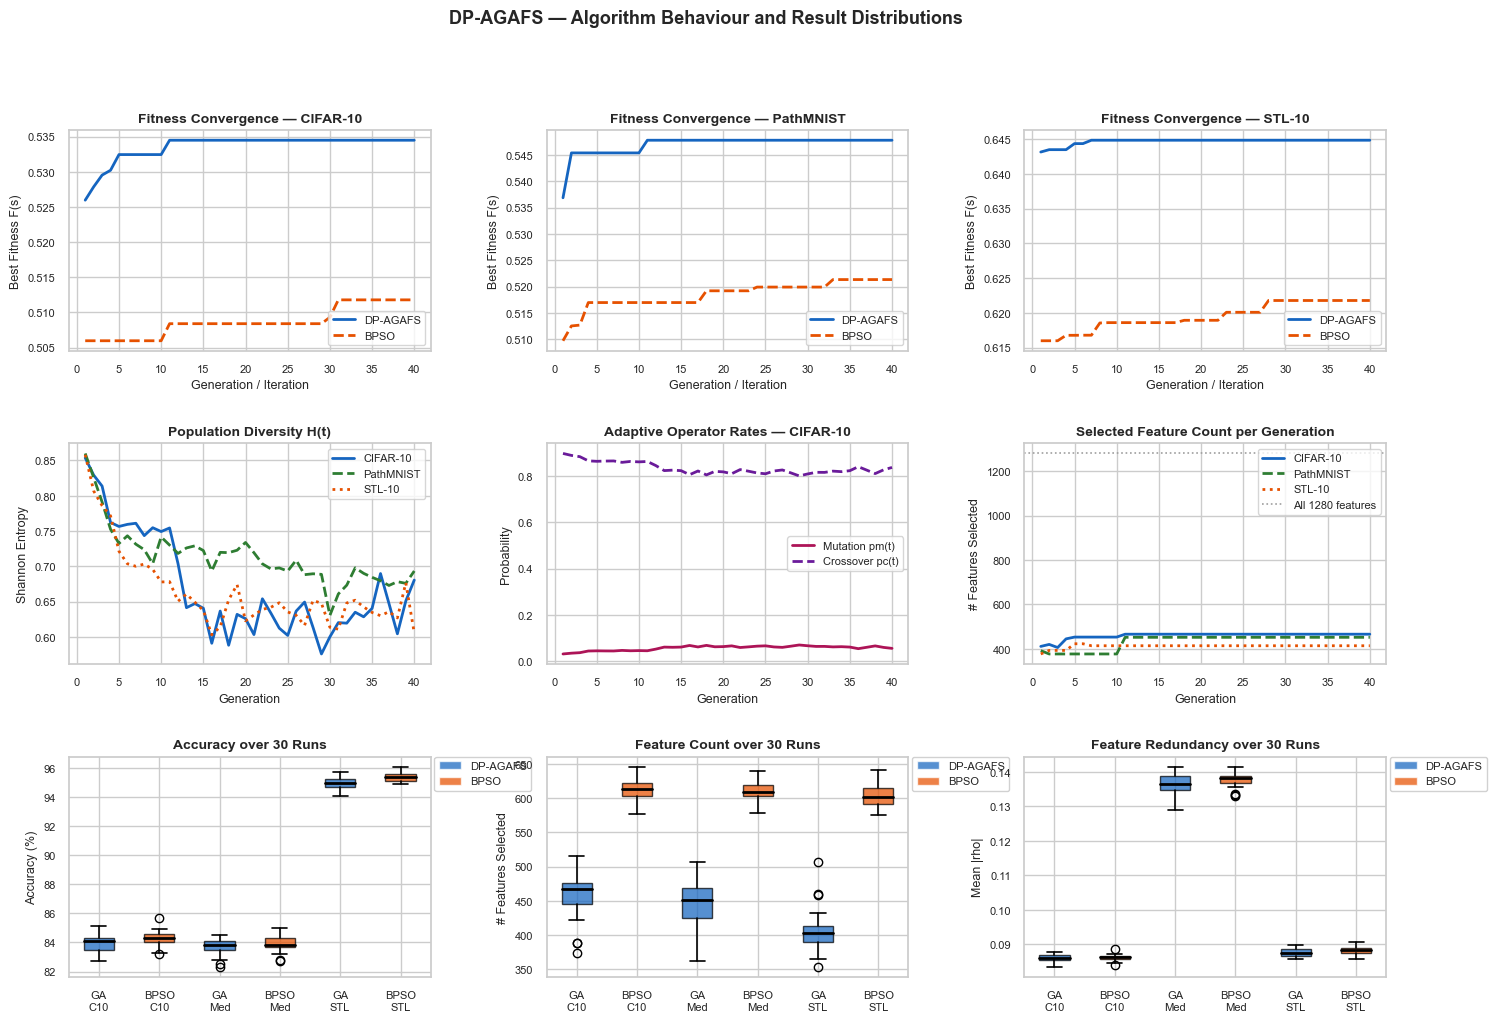

Saved: image1_algorithm_behaviour.png


In [36]:
sns.set_theme(style='whitegrid', font_scale=0.95)
C = '#1565C0'; O = '#E65100'; G = '#2E7D32'

best_ga_c  = max(ga_cifar,  key=lambda r: r['acc'])
best_pso_c = max(pso_cifar, key=lambda r: r['acc'])
best_ga_m  = max(ga_med,    key=lambda r: r['acc'])
best_pso_m = max(pso_med,   key=lambda r: r['acc'])
best_ga_s  = max(ga_stl,    key=lambda r: r['acc'])
best_pso_s = max(pso_stl,   key=lambda r: r['acc'])

gens_ga  = range(1, CFG['n_generations'] + 1)
gens_pso = range(1, CFG['pso_iters'] + 1)
N_FEAT   = len(best_chrom_cifar)

fig = plt.figure(figsize=(17, 11))
fig.patch.set_facecolor('white')
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.32)
fig.suptitle('DP-AGAFS — Algorithm Behaviour and Result Distributions',
             fontsize=13, fontweight='bold', y=0.99)

# Row 1: Convergence
for col, (dsname, bga, bpso) in enumerate([
    ('CIFAR-10',  best_ga_c, best_pso_c),
    ('PathMNIST', best_ga_m, best_pso_m),
    ('STL-10',    best_ga_s, best_pso_s),
]):
    ax = fig.add_subplot(gs[0, col])
    ax.plot(gens_ga,  bga['hist']['best'],  color=C, lw=2,         label='DP-AGAFS')
    ax.plot(gens_pso, bpso['hist']['best'], color=O, lw=2, ls='--', label='BPSO')
    ax.set_title('Fitness Convergence — ' + dsname,
                 fontsize=10, fontweight='bold')
    ax.set_xlabel('Generation / Iteration', fontsize=9)
    ax.set_ylabel('Best Fitness F(s)', fontsize=9)
    ax.legend(fontsize=8, loc='lower right')
    ax.tick_params(labelsize=8)

# Row 2: H(t) | Adaptive rates | Feature count
ax = fig.add_subplot(gs[1, 0])
ax.plot(gens_ga, best_ga_c['hist']['H'], color=C, lw=2,         label='CIFAR-10')
ax.plot(gens_ga, best_ga_m['hist']['H'], color=G, lw=2, ls='--', label='PathMNIST')
ax.plot(gens_ga, best_ga_s['hist']['H'], color=O, lw=2, ls=':',  label='STL-10')
ax.set_title('Population Diversity H(t)', fontsize=10, fontweight='bold')
ax.set_xlabel('Generation', fontsize=9)
ax.set_ylabel('Shannon Entropy', fontsize=9)
ax.legend(fontsize=8, loc='upper right')
ax.tick_params(labelsize=8)

ax = fig.add_subplot(gs[1, 1])
ax.plot(gens_ga, best_ga_c['hist']['pm'], color='#AD1457', lw=2,         label='Mutation pm(t)')
ax.plot(gens_ga, best_ga_c['hist']['pc'], color='#6A1B9A', lw=2, ls='--', label='Crossover pc(t)')
ax.set_title('Adaptive Operator Rates — CIFAR-10', fontsize=10, fontweight='bold')
ax.set_xlabel('Generation', fontsize=9)
ax.set_ylabel('Probability', fontsize=9)
ax.legend(fontsize=8)
ax.tick_params(labelsize=8)

ax = fig.add_subplot(gs[1, 2])
ax.plot(gens_ga, best_ga_c['hist']['nf'], color=C, lw=2,         label='CIFAR-10')
ax.plot(gens_ga, best_ga_m['hist']['nf'], color=G, lw=2, ls='--', label='PathMNIST')
ax.plot(gens_ga, best_ga_s['hist']['nf'], color=O, lw=2, ls=':',  label='STL-10')
ax.axhline(N_FEAT, color='#9E9E9E', ls=':', lw=1.2, label='All ' + str(N_FEAT) + ' features')
ax.set_title('Selected Feature Count per Generation', fontsize=10, fontweight='bold')
ax.set_xlabel('Generation', fontsize=9)
ax.set_ylabel('# Features Selected', fontsize=9)
ax.legend(fontsize=8, loc='upper right')
ax.tick_params(labelsize=8)

# Row 3: Box plots — accuracy | feature count | redundancy
ds_labels = ['GA\nC10', 'BPSO\nC10', 'GA\nMed', 'BPSO\nMed', 'GA\nSTL', 'BPSO\nSTL']
bp_colors = [C, O, C, O, C, O]

for col, (data_fn, ylabel, title) in enumerate([
    (lambda: [
        [r['acc']*100 for r in ga_cifar],  [r['acc']*100 for r in pso_cifar],
        [r['acc']*100 for r in ga_med],    [r['acc']*100 for r in pso_med],
        [r['acc']*100 for r in ga_stl],    [r['acc']*100 for r in pso_stl],
     ], 'Accuracy (%)', 'Accuracy over ' + str(CFG['n_runs']) + ' Runs'),
    (lambda: [
        [r['nf'] for r in ga_cifar],  [r['nf'] for r in pso_cifar],
        [r['nf'] for r in ga_med],    [r['nf'] for r in pso_med],
        [r['nf'] for r in ga_stl],    [r['nf'] for r in pso_stl],
     ], '# Features Selected', 'Feature Count over ' + str(CFG['n_runs']) + ' Runs'),
    (lambda: [
        [r['rho'] for r in ga_cifar],  [r['rho'] for r in pso_cifar],
        [r['rho'] for r in ga_med],    [r['rho'] for r in pso_med],
        [r['rho'] for r in ga_stl],    [r['rho'] for r in pso_stl],
     ], 'Mean |rho|', 'Feature Redundancy over ' + str(CFG['n_runs']) + ' Runs'),
]):
    ax = fig.add_subplot(gs[2, col])
    bp = ax.boxplot(
        data_fn(), patch_artist=True, labels=ds_labels,
        medianprops={'color': 'black', 'lw': 2},
        whiskerprops={'lw': 1.2}, capprops={'lw': 1.2},
    )
    for patch, col_c in zip(bp['boxes'], bp_colors):
        patch.set_facecolor(col_c)
        patch.set_alpha(0.72)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', labelsize=8)
    ax.tick_params(axis='y', labelsize=8)
    # Legend outside right so it never covers the data
    legend_elems = [
        plt.Rectangle((0,0),1,1, fc=C, alpha=0.72, label='DP-AGAFS'),
        plt.Rectangle((0,0),1,1, fc=O, alpha=0.72, label='BPSO'),
    ]
    ax.legend(handles=legend_elems, fontsize=8,
              loc='upper left', bbox_to_anchor=(1.01, 1),
              borderaxespad=0, framealpha=0.9)

fig.savefig(
    os.path.join(FIGURES_DIR, 'image1_algorithm_behaviour.png'),
    dpi=600, bbox_inches='tight', facecolor='white',
)
plt.show()
plt.close(fig)
print("Saved: image1_algorithm_behaviour.png")

NameError: name 'cols_oh' is not defined

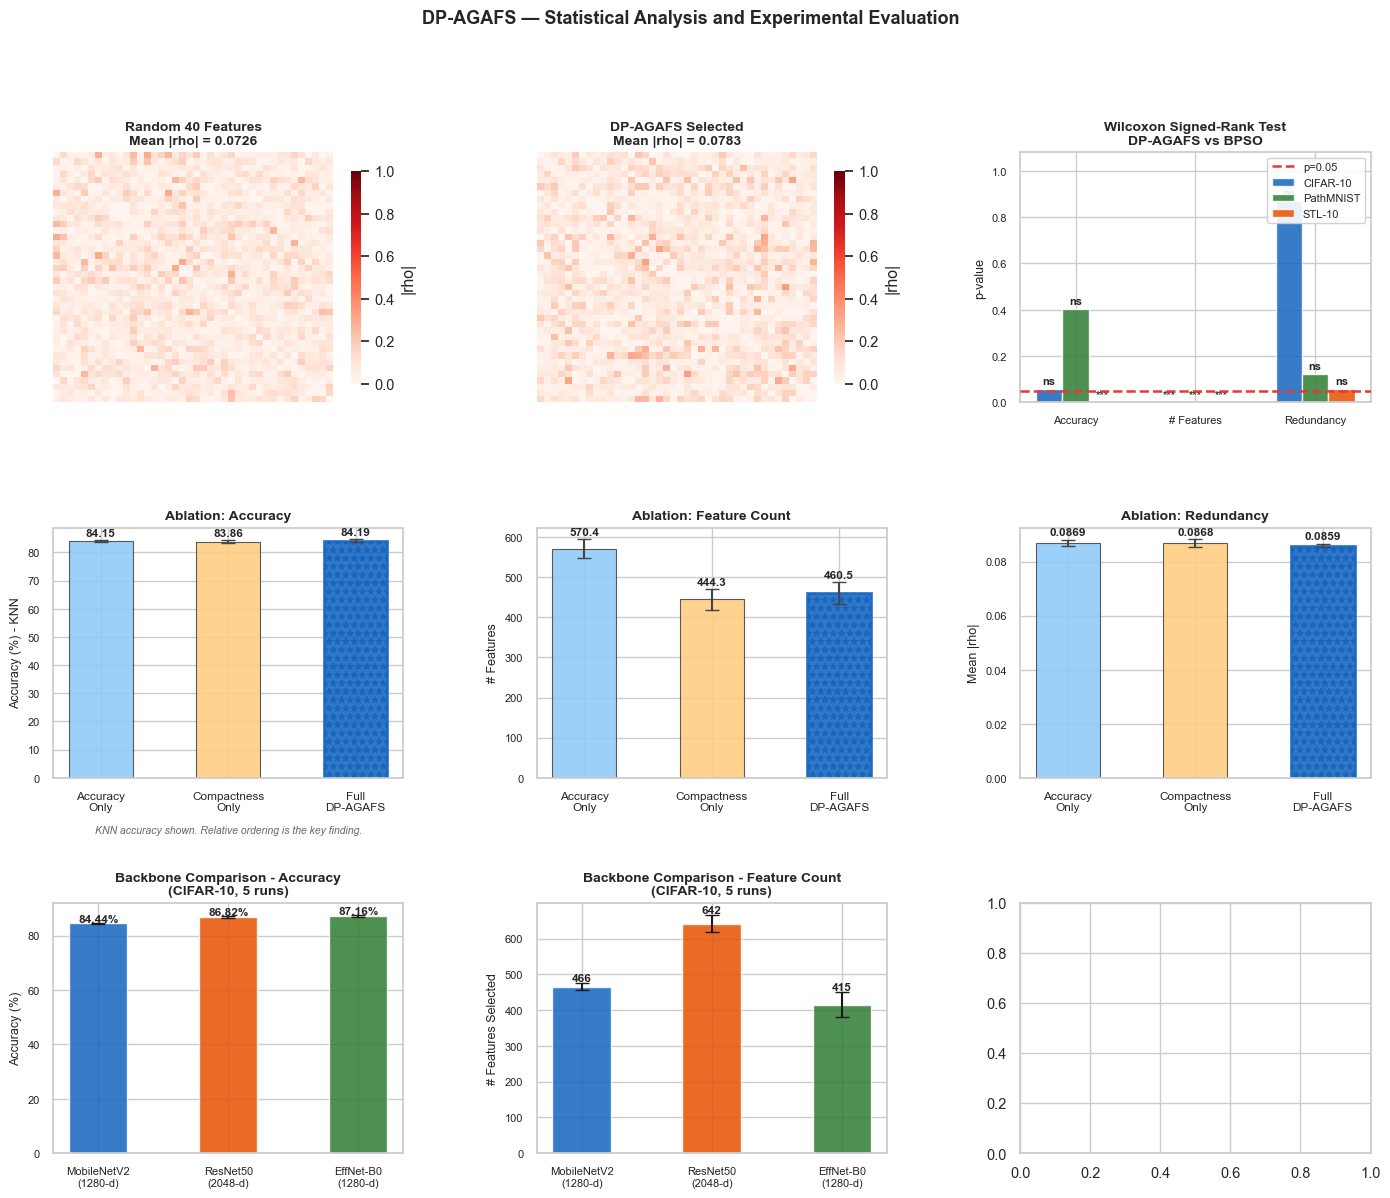

In [37]:
# ---- aliases so the existing figure cell (image2) finds what it expects ----
overhead['corr_penalty_ms']    = overhead['corr_penalty_ms_chrom']   # per-chromosome
overhead['eval_s']             = overhead['gpu_gen_ms'] / 1000 / M    # per-chromosome GPU fitness, seconds
overhead['one_gen_s']          = overhead['gpu_gen_ms'] / 1000        # one generation, seconds
overhead['novel_total_ms']     = overhead['novel_ms_gen']
overhead['novel_overhead_pct'] = overhead['novel_pct_gpu_gen']
overhead['corr_gpu_s']         = overhead['corr_gpu_ms'] / 1000

sns.set_theme(style='whitegrid', font_scale=0.95)
C = '#1565C0'; O = '#E65100'; G = '#2E7D32'

fig = plt.figure(figsize=(17, 13))
fig.patch.set_facecolor('white')
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.50, wspace=0.38)
fig.suptitle('DP-AGAFS — Statistical Analysis and Experimental Evaluation',
             fontsize=13, fontweight='bold', y=0.99)

N_FEAT   = len(best_chrom_cifar)
sel_idx  = np.where(best_chrom_cifar == 1)[0][:40]
rand_idx = np.random.RandomState(SEED).choice(N_FEAT, 40, replace=False)

# Row 1, Col 0-1: Correlation heatmaps
try:
    rand_corr = CORR_C[np.ix_(rand_idx, rand_idx)]
    sel_corr  = CORR_C[np.ix_(sel_idx,  sel_idx)]
    rand_mean = round(float(rand_corr.mean()), 4)
    sel_mean  = round(float(sel_corr.mean()),  4)

    ax = fig.add_subplot(gs[0, 0])
    sns.heatmap(rand_corr, ax=ax, cmap='Reds', vmin=0, vmax=1,
                xticklabels=False, yticklabels=False,
                cbar_kws={'label': '|rho|', 'shrink': 0.85})
    ax.set_title('Random 40 Features\nMean |rho| = ' + str(rand_mean),
                 fontsize=10, fontweight='bold')

    ax = fig.add_subplot(gs[0, 1])
    sns.heatmap(sel_corr, ax=ax, cmap='Reds', vmin=0, vmax=1,
                xticklabels=False, yticklabels=False,
                cbar_kws={'label': '|rho|', 'shrink': 0.85})
    ax.set_title('DP-AGAFS Selected\nMean |rho| = ' + str(sel_mean),
                 fontsize=10, fontweight='bold')
except NameError:
    for c in [0, 1]:
        ax = fig.add_subplot(gs[0, c])
        ax.text(0.5, 0.5, 'CORR_C not in memory.\nRe-run Phase 2 Cell 4.',
                ha='center', va='center', transform=ax.transAxes, fontsize=9)
        ax.set_title('Correlation Heatmap', fontsize=10)

# Row 1, Col 2: Wilcoxon p-values
ax = fig.add_subplot(gs[0, 2])
metrics_w   = ['Accuracy', '# Features', 'Redundancy']
metrics_key = ['Accuracy (%)', '# Features', 'Mean |rho|']
w_list      = [w_cifar, w_med, w_stl]
ds_names    = ['CIFAR-10', 'PathMNIST', 'STL-10']
ds_cols     = [C, G, O]
x3 = np.arange(len(metrics_w)); wb = 0.22

for di, (ds, wd, col) in enumerate(zip(ds_names, w_list, ds_cols)):
    pvals = [wd[mk]['p'] for mk in metrics_key]
    bars  = ax.bar(x3 + (di-1)*wb, pvals, wb,
                   label=ds, color=col, alpha=0.85, edgecolor='white')
    for bar, pv in zip(bars, pvals):
        sig = '***' if pv<0.001 else ('**' if pv<0.01
              else ('*' if pv<0.05 else 'ns'))
        ax.text(bar.get_x() + bar.get_width()/2,
                min(pv + 0.02, 0.92),
                sig, ha='center', fontsize=8, fontweight='bold')

ax.axhline(0.05, color='#E53935', ls='--', lw=1.8, label='p=0.05', zorder=5)
ax.set_xticks(x3); ax.set_xticklabels(metrics_w, fontsize=9)
ax.set_ylabel('p-value', fontsize=9)
ax.set_ylim(0, 1.08)
ax.set_title('Wilcoxon Signed-Rank Test\nDP-AGAFS vs BPSO', fontsize=10, fontweight='bold')
ax.legend(fontsize=8, loc='upper right', framealpha=0.9)
ax.tick_params(labelsize=8)

# Row 2: Ablation — accuracy | feature count | redundancy
ab_keys   = ['accuracy_only', 'compactness_only', 'full_dp_agafs']
ab_labels = ['Accuracy\nOnly', 'Compactness\nOnly', 'Full\nDP-AGAFS']
ab_colors = ['#90CAF9', '#FFCC80', C]

for col, (mk, ek, ylabel, title, scale) in enumerate(zip(
    ['acc_mean', 'nf_mean',  'rho_mean'],
    ['acc_std',  'nf_std',   'rho_std'],
    ['Accuracy (%) - KNN', '# Features', 'Mean |rho|'],
    ['Ablation: Accuracy', 'Ablation: Feature Count', 'Ablation: Redundancy'],
    [100, 1, 1],
)):
    ax   = fig.add_subplot(gs[1, col])
    vals = [ablation_results[k][mk] * scale for k in ab_keys]
    errs = [ablation_results[k][ek] * scale for k in ab_keys]

    bars = ax.bar(ab_labels, vals, yerr=errs,
                  color=ab_colors, alpha=0.88, width=0.5,
                  edgecolor='#444', linewidth=0.8, capsize=5,
                  error_kw={'elinewidth': 1.5, 'ecolor': '#444'})
    bars[2].set_hatch('**')
    bars[2].set_edgecolor(C)
    bars[2].set_linewidth(2)

    ax.set_ylabel(ylabel, fontsize=9)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', labelsize=8.5)
    ax.tick_params(axis='y', labelsize=8)

    for bar, v, e in zip(bars, vals, errs):
        fmt = (str(round(v, 2)) if scale == 100
               else str(round(v, 1)) if v > 10
               else str(round(v, 4)))
        ax.text(bar.get_x() + bar.get_width()/2,
                v + e + max(vals)*0.018,
                fmt, ha='center', fontsize=8.5, fontweight='bold')

    if col == 0:
        ax.text(0.5, -0.22,
                'KNN accuracy shown. Relative ordering is the key finding.',
                ha='center', transform=ax.transAxes,
                fontsize=7.5, color='#666', style='italic')

# Row 3, Col 0-1: Backbone comparison
bb_names  = list(backbone_results.keys())
bb_labels = ['MobileNetV2\n(1280-d)', 'ResNet50\n(2048-d)', 'EffNet-B0\n(1280-d)']
bb_acc    = [backbone_results[n]['acc_mean']*100 for n in bb_names]
bb_err    = [backbone_results[n]['acc_std']*100  for n in bb_names]
bb_nf     = [backbone_results[n]['nf_mean']      for n in bb_names]
bb_nf_e   = [backbone_results[n]['nf_std']       for n in bb_names]
bb_cols   = [C, O, G]

ax = fig.add_subplot(gs[2, 0])
bars = ax.bar(bb_labels, bb_acc, yerr=bb_err,
              color=bb_cols, alpha=0.85, width=0.45, capsize=5,
              edgecolor='white', error_kw={'elinewidth': 1.5})
ax.set_ylabel('Accuracy (%)', fontsize=9)
ax.set_title('Backbone Comparison - Accuracy\n(CIFAR-10, 5 runs)',
             fontsize=10, fontweight='bold')
ax.tick_params(labelsize=8)
for bar, v, e in zip(bars, bb_acc, bb_err):
    ax.text(bar.get_x() + bar.get_width()/2, v+e+0.2,
            str(round(v, 2)) + '%',
            ha='center', fontsize=8.5, fontweight='bold')

ax = fig.add_subplot(gs[2, 1])
bars2 = ax.bar(bb_labels, bb_nf, yerr=bb_nf_e,
               color=bb_cols, alpha=0.85, width=0.45, capsize=5,
               edgecolor='white', error_kw={'elinewidth': 1.5})
ax.set_ylabel('# Features Selected', fontsize=9)
ax.set_title('Backbone Comparison - Feature Count\n(CIFAR-10, 5 runs)',
             fontsize=10, fontweight='bold')
ax.tick_params(labelsize=8)
for bar, v, e in zip(bars2, bb_nf, bb_nf_e):
    ax.text(bar.get_x() + bar.get_width()/2, v+e+5,
            str(int(round(v, 0))),
            ha='center', fontsize=8.5, fontweight='bold')

# Row 3, Col 2: Overhead breakdown
ax = fig.add_subplot(gs[2, 2])

nov_ms  = overhead.get('novel_total_ms',
    overhead['entropy_ms'] + overhead['adaptive_ms']
    + overhead['corr_penalty_ms'] * CFG['pop_size'])
knn_ms  = overhead['eval_s'] * 1000 * CFG['pop_size']
nov_pct = overhead.get('novel_overhead_pct',
    nov_ms / (overhead['one_gen_s'] * 1000) * 100)

labels_oh = ['Entropy\nH(t)', 'Adaptive\nRates', 'Corr.\nPenalty', 'KNN fitness\n(GPU)']
vals_oh   = [overhead['entropy_ms'], overhead['adaptive_ms'],
             overhead['corr_penalty_ms'] * CFG['pop_size'], knn_ms]

# floor tiny values so log scale doesn't explode
vals_plot = [max(v, 1e-3) for v in vals_oh]

bars3 = ax.bar(labels_oh, vals_plot, color=cols_oh,
               alpha=0.85, width=0.5, edgecolor='white')
ax.set_yscale('log')
ax.set_ylim(1e-3, max(vals_plot) * 3)   # explicit range prevents the blow-up
ax.set_ylabel('Time per Generation (ms, log scale)', fontsize=9)
ax.set_title('Computational Overhead\nNovel = ' + str(round(nov_pct, 3)) + '% of gen. time',
             fontsize=10, fontweight='bold')
ax.tick_params(labelsize=8)
for bar, v in zip(bars3, vals_oh):   # label with the REAL value, not the floored one
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() * 1.35,
            str(round(v, 3)),
            ha='center', fontsize=8, fontweight='bold')

fig.savefig(
    os.path.join(FIGURES_DIR, 'image2_analysis.png'),
    dpi=200, bbox_inches='tight', facecolor='white',
)
plt.show()
plt.close(fig)
print("Saved: image2_analysis.png")

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
import numpy as np

# Load best chromosomes
best_c = np.load('./dp_agafs_results/best_chrom_cifar.npy')
best_m = np.load('./dp_agafs_results/best_chrom_pathmnist.npy')
best_s = np.load('./dp_agafs_results/best_chrom_stl10.npy')

classifiers = {
    'SVM (RBF)'          : SVC(kernel='rbf', C=1, gamma='scale'),
    'KNN (k=5)'          : KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    'Random Forest'      : RandomForestClassifier(n_estimators=100,
                                                   n_jobs=-1, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000,
                                               random_state=42, n_jobs=-1),
    'MLP (1 hidden)'     : MLPClassifier(hidden_layer_sizes=(256,),
                                          max_iter=300, random_state=42),
}

datasets_clf = [
    ('CIFAR-10',  best_c, Xc_tr, yc_tr, Xc_te, yc_te),
    ('PathMNIST', best_m, Xm_tr, ym_tr, Xm_te, ym_te),
    ('STL-10',    best_s, Xs_tr, ys_tr, Xs_te, ys_te),
]

print("="*70)
print(f"  CLASSIFIER GENERALISATION STUDY")
print("="*70)
print(f"{'Dataset':<12} {'Classifier':<22} {'All feats':>10} {'Selected':>10} {'Diff':>8}")
print("-"*70)

clf_results = {}
for ds_name, chrom, Xtr, ytr, Xte, yte in datasets_clf:
    idx = np.where(chrom == 1)[0]
    clf_results[ds_name] = {}
    for clf_name, clf in classifiers.items():
        # All features
        clf.fit(Xtr, ytr)
        acc_all = accuracy_score(yte, clf.predict(Xte))
        # Selected features
        clf.fit(Xtr[:, idx], ytr)
        acc_sel = accuracy_score(yte, clf.predict(Xte[:, idx]))
        diff = acc_sel - acc_all
        clf_results[ds_name][clf_name] = {
            'acc_all': acc_all, 'acc_sel': acc_sel, 'diff': diff
        }
        print(f"{ds_name:<12} {clf_name:<22} "
              f"{acc_all*100:>9.2f}%  {acc_sel*100:>9.2f}%  "
              f"{diff*100:>+7.2f}%")
    print()

import json
with open('./dp_agafs_results/classifier_generalisation.json', 'w') as f:
    json.dump({ds: {clf: {k: float(v) for k,v in r.items()}
               for clf, r in res.items()}
               for ds, res in clf_results.items()}, f, indent=2)
print("Saved: classifier_generalisation.json")

In [ ]:
print("=" * 55)
print("  FINAL SUBMISSION CHECKLIST")
print("=" * 55)

checks = [
    ("master_results.json saved",
     os.path.exists(os.path.join(RESULTS_DIR, 'master_results.json'))),
    ("statistical_analysis.json saved",
     os.path.exists(os.path.join(RESULTS_DIR, 'statistical_analysis.json'))),
    ("image1_algorithm_behaviour.png saved",
     os.path.exists(os.path.join(FIGURES_DIR, 'image1_algorithm_behaviour.png'))),
    ("image2_analysis.png saved",
     os.path.exists(os.path.join(FIGURES_DIR, 'image2_analysis.png'))),
    ("CIFAR-10 GA runs = " + str(CFG['n_runs']),
     len(ga_cifar) == CFG['n_runs']),
    ("CIFAR-10 PSO runs = " + str(CFG['n_runs']),
     len(pso_cifar) == CFG['n_runs']),
    ("PathMNIST GA runs = " + str(CFG['n_runs']),
     len(ga_med) == CFG['n_runs']),
    ("STL-10 GA runs = " + str(CFG['n_runs']),
     len(ga_stl) == CFG['n_runs']),
    ("Ablation has 3 variants",
     len(ablation_results) == 3),
    ("Backbone comparison has 3",
     len(backbone_results) == 3),
    ("Overhead data present",
     'entropy_ms' in overhead),
    ("Wilcoxon results computed",
     'binomial' in w_cifar),
]

all_ok = True
for label, status in checks:
    mark = "PASS" if status else "FAIL"
    print(f"  [{mark}]  {'OK' if status else '!!'}  {label}")
    if not status:
        all_ok = False

print()
if all_ok:
    print("All checks passed.")
    print()
    print("Next steps:")
    print("  1. Fill Tables 2,3,4,5 in LaTeX using Cell 3 output")
    print("  2. Insert image1_algorithm_behaviour.png as Fig. 2")
    print("  3. Insert image2_analysis.png as Fig. 3")
    print("  4. Paste Section V text from Cell 6 into paper")
    print("  5. Paste Section IV-F paragraph from Cell 6 into paper")
    print("  6. Paste reviewer response from Cell 6 into cover letter")
    print("  7. Submit before July 20th")
else:
    print("Some checks failed. Re-run the corresponding Phase 4 cells.")

print()
print("Figures saved:")
for fname in sorted(os.listdir(FIGURES_DIR)):
    fpath = os.path.join(FIGURES_DIR, fname)
    sz    = os.path.getsize(fpath) / 1024
    print(f"  {fname:<45}  {sz:>7.1f} KB")

In [ ]:
# ============================================================
#  REPRODUCIBILITY TEST — CIFAR-10, independent seed set
#  Safe: uses _repro variable names, does NOT touch real results.
# ============================================================
import numpy as np, time, json, os
from scipy.stats import wilcoxon, binomtest

REPRO_RUNS  = 30           # match your main run count
REPRO_SEED0 = SEED + 1000  # different seed base -> independent draws

# make sure CIFAR is resident for the GPU fitness
set_gpu_dataset('cifar', Xc_tr, yc_tr, Xc_te, yc_te)

print("="*60)
print(f"  REPRODUCIBILITY TEST (CIFAR-10, {REPRO_RUNS} runs, seed base {REPRO_SEED0})")
print("="*60)

ga_nf_repro,  ga_acc_repro  = [], []
pso_nf_repro, pso_acc_repro = [], []

t_start = time.time()
for run in range(REPRO_RUNS):
    # --- GA ---
    np.random.seed(REPRO_SEED0 + run)
    chrom_g, _ = run_ga(Xc_tr, yc_tr, Xc_te, yc_te, CORR_C, CFG, verbose=False)
    ga_nf_repro.append(int(chrom_g.sum()))
    ga_acc_repro.append(eval_accuracy(chrom_g, Xc_tr, yc_tr, Xc_te, yc_te, 'svm'))

    # --- PSO ---
    np.random.seed(REPRO_SEED0 + run)
    chrom_p, _ = run_pso(Xc_tr, yc_tr, Xc_te, yc_te, CORR_C, CFG, verbose=False)
    pso_nf_repro.append(int(chrom_p.sum()))
    pso_acc_repro.append(eval_accuracy(chrom_p, Xc_tr, yc_tr, Xc_te, yc_te, 'svm'))

    if (run+1) % 5 == 0:
        print(f"  run {run+1:2d}/{REPRO_RUNS}  "
              f"GA nf={ga_nf_repro[-1]:3d} acc={ga_acc_repro[-1]*100:.2f}%")

elapsed = time.time() - t_start

ga_nf_repro  = np.array(ga_nf_repro);  ga_acc_repro  = np.array(ga_acc_repro)
pso_nf_repro = np.array(pso_nf_repro); pso_acc_repro = np.array(pso_acc_repro)

# --- stats ---
w_nf  = wilcoxon(ga_nf_repro,  pso_nf_repro).pvalue
n_fewer = int((ga_nf_repro < pso_nf_repro).sum())
binom_p = binomtest(n_fewer, REPRO_RUNS, 0.5, alternative='greater').pvalue

print("\n" + "-"*60)
print(f"  DP-AGAFS  : acc={ga_acc_repro.mean()*100:.2f}±{ga_acc_repro.std()*100:.2f}%  "
      f"nf={ga_nf_repro.mean():.1f}±{ga_nf_repro.std():.1f}")
print(f"  BPSO      : acc={pso_acc_repro.mean()*100:.2f}±{pso_acc_repro.std()*100:.2f}%  "
      f"nf={pso_nf_repro.mean():.1f}±{pso_nf_repro.std():.1f}")
print(f"  Feature reduction Wilcoxon p = {w_nf:.2e}")
print(f"  GA fewer features: {n_fewer}/{REPRO_RUNS}  (binomial p = {binom_p:.2e})")
print(f"  Time: {elapsed/60:.1f} min")

# --- comparison to your MAIN run (from statistical_analysis.json values) ---
MAIN_GA_NF, MAIN_GA_ACC = 458.8, 83.92    # your reported CIFAR DP-AGAFS
print("\n  vs MAIN run:")
print(f"    #features : main {MAIN_GA_NF:.1f}  |  repro {ga_nf_repro.mean():.1f}  "
      f"|  diff {abs(MAIN_GA_NF-ga_nf_repro.mean()):.1f}")
print(f"    accuracy  : main {MAIN_GA_ACC:.2f}%  |  repro {ga_acc_repro.mean()*100:.2f}%  "
      f"|  diff {abs(MAIN_GA_ACC-ga_acc_repro.mean()*100):.2f}%")

# --- verdict ---
nf_ok  = abs(MAIN_GA_NF - ga_nf_repro.mean()) < 25      # within ~25 features
acc_ok = abs(MAIN_GA_ACC - ga_acc_repro.mean()*100) < 1 # within 1%
sig_ok = w_nf < 0.001
print("\n  " + ("REPRODUCIBLE ✓" if (nf_ok and acc_ok and sig_ok)
                else "CHECK — larger deviation than expected"))

# --- save to its OWN file (does not touch master_results.json) ---
with open(os.path.join(RESULTS_DIR, 'reproducibility_test.json'), 'w') as f:
    json.dump({
        'seed_base'      : REPRO_SEED0,
        'n_runs'         : REPRO_RUNS,
        'ga_nf_mean'     : float(ga_nf_repro.mean()),
        'ga_nf_std'      : float(ga_nf_repro.std()),
        'ga_acc_mean'    : float(ga_acc_repro.mean()),
        'pso_nf_mean'    : float(pso_nf_repro.mean()),
        'pso_acc_mean'   : float(pso_acc_repro.mean()),
        'wilcoxon_nf_p'  : float(w_nf),
        'binomial_p'     : float(binom_p),
        'n_ga_fewer'     : n_fewer,
    }, f, indent=2)
print("  saved: reproducibility_test.json")